# Visualización de imágenes por panoid

La búsqueda recorre todos los parquets y conserva todos los resultados y columnas de metadatos en `df_panoid`, sin cargar los bytes de imagen en RAM.

Las fotos y la tabla se muestran por páginas. Cambiá `PAGINA` (desde 1) y ejecutá únicamente la última celda para navegar sin repetir la búsqueda. `IMAGENES_POR_PAGINA` controla el tamaño de cada página; `TAMANO_MINIATURA` limita la resolución mostrada.

`ORDENAR_POR_PAIS` ordena todos los resultados por país. Si el kernel perdió su carpeta de trabajo, configurá `RAIZ_PROYECTO`. Reiniciá el kernel antes de ejecutar esta versión si la anterior dejó imágenes en memoria.


In [ ]:
# Cambiar estos valores y volver a ejecutar las celdas siguientes.
PANOIDS = [
"0soYmumnzvHhPwYZkKneQ",
"3H8ZcGBfQm-Yxd1h5R5Jg",
"3NWh1fxjOVbbEmlkV8B6Q",
"5_53iUy1kVrib6h2IvhbA",
"6ljIemRcpE78DB3_t2ERw",
"6swcCd2Ec0b8lBjqIFAcA",
"91OJYywJrUVqTF7DH29CA",
"A0YIOEm2Ak-FIjYsHelew",
"C3ODru98UXpfxXjCG3J4Q",
"E7KdUExo8OKm1AEdsUXZA",
"Gtn4Z54g4tDyfpEPG8cpQ",
"H3H9WrcjIFsYkd8uEb6gA",
"ICU7H4-BsmX7QBwGlhC3w",
"K4HoOg8MMvBtaT6XC1SiQ",
"MJlEC0pS4h8_nE-PrvuvA",
"PrR4wQnRNNCVwMIul4NvQ",
"QbG624YyILI-ZY6x8qT6Q",
"U17g7FAR_v0WGvSJnC_fg",
"UhLSaM_Rslja7zPtC35Mg",
"VwoY61RoIFjvWDF8Fa8qQ",
"X9MwDJWGOtGEEmDr6n8JQ",
"XVF69PpbQ6s8M75ai4Ssg",
"_atwI2pBZdQ9SN7_GXQog",
"a9AJpglzZYoka-lEIxLxw",
"aUn2LznL9BVTqMVn3CqsA",
"bQ1GKvfrBA7E02OszTvvA",
"bR_kayAP5tkRTo3QBmf9w",
"bXRwoAzPd3Hfv2v54-Nkg",
"baP1C2WRFkEJwvs00PDOg",
"eeI7m24xH9f0wv5m55fmg",
"f5x-7gXJTOPU7f8f83OAw",
"fW59oXHDoASRqS3BK7fLQ",
"ffNfTNvWXdwixBVV-bumA",
"gKoVL1KuL1P2U3Zf_yLbQ",
"iLheMzqIqn1MFusnCxhrQ",
"kCZkc8wHfMtJZamL8pjNA",
"kpxHXFrN0CFy6Pf9QIfsg",
"l_T-MjlQAJp4rpY9QbDDA",
"qZ8_Zeb05Ly4IHLCo4TOw",
"qpni1plvKaBkIBnkkzFXg",
"sILJDEBvu8Laz7JRFLUSQ",
"sT1sGixb08Bu5yB005ozw",
"t28Zv7JvpnQwwrRcJGAlw",
"t9ZgH1IC9HDBPJSgYZL9w",
"tmk-4YS93RifY6re8aRgw",
"uQvgHQ-rPyv2fm1fG517w",
"x0t4j-FkzArOhV5JZ082A",
"yjE93DvN6twWQqu1CX2NA",
"zH7F8h8fk_rdRGbsTb1JQ",
"zU6BDN2QlQfaaPWD3FmWQ",
"-3_KGgUsjImOnZh-aiNeA",
"-3fTnZ7P7JUxZEtqSfQ9A",
"3TAFF7Ca352OujMC5y_4A",
"7mT_Ykj4W8Hop0gEhf21Q",
"9RK-5NPz5Z_irQv-qGKkg",
"Fcet4TYEeVlebp455pl5Q",
"IJIP4x0HXzUFDTPCv3pVA",
"LvEDIJBLn0BNl6Y5T8RcQ",
"M9umeS0gFULsCAoZsXR3g",
"O9-nveWYaNUpYGXWYPktQ",
"OModGn5POvkF7NTcNzzyw",
"PcBQLey_8V9AvUvM1sKNw",
"QUOboKwSzB2M02p0okL5A",
"QrPSD4eMUkXwkJXXBBAtw",
"R7r1HQDywKcsqInfUUawA",
"ScVHQ16PYxMOpOptjfxag",
"Tfm9fm3KVwEZghLKm7zxA",
"Uwv4Efbj4vq2F8LKmoJ5g",
"ZiW3jQ-zZTkGPK0bPHJog",
"ZprwhsTXa0EqIfszWjx9g",
"apGaYpaad2DWQZraJ3c8g",
"au3L9V36sX2HgwuZcj1fw",
"dgcVdVvvvi5KR-iR04A1Q",
"eTbow3y9J8kwoqhduFBoQ",
"gyKncwTOWCYV6uPKSkFrA",
"hEY5R3E_HfzYCcuI6Dh8Q",
"hvWfEDHFQxcsnEhM8BD0w",
"iPFBi9zvjztSAoGzKIBYw",
"iVEoTU4bmZPqeo70G7tTw",
"jfko5JRF9mDCDrxgfG8aw",
"mGnROExm7KdwXmmWNLAoA",
"mJy8S_GNXlt9s06unexsg",
"nZ6YIPPQKgDsajJMsjGng",
"nbtf6rE0dSQsAQvjHaEgA",
"oBX-SbbpoShUV2GDrZI9Q",
"pRoX-PwSP4x4aKT1Bs6zw",
"rzoT6BfE1sZxQuAtb1H4w",
"sa91oE3hT_E-AjgIQ2VzQ",
"uYBmugMN6VS173P8mDGGg",
"vKRbC11_hL0HH1VBP6FgA",
"vzlhXc2jKKHoj-qA9mWng",
"wD3bL9oZ5RuQDEzrgYYDg",
"-Ul_kmU_PVbCgQr-AKM1w",
"-nV4NrBcIkdy3hWBOrxSg",
"-pFn-CwjZrCYXMxAjAFdw",
"1croiTQ63QmKA4ewTJ9Eg",
"3WtYhfFBxwV482qfmjARw",
"3ZOa_C0QE3c31InWR9kAQ",
"6Gp4otzBuWZLkI40K9UBA",
"7yBXrr3akN_c5oAvvTrEg",
"9khejW3tuNeNZcFwoeZpA",
"Ad2h7UuljovJ5PEI07JLA",
"DL2OpRzZEpZdXx1oxiUbg",
"EBYjPLLErzoySctqUfvVQ",
"Ewb1XgHatZ5R0nnGIjLoQ",
"FEMQUPBO9bb_38jxWqp5A",
"IMcMQVJ-Hlbn-aiE7Fi7Q",
"LUctRMPcTdMeLnIOYiQYA",
"Ly_oPRm-72PFkMQqXedrA",
"MXmrzHX4adURBr3gihB4w",
"O7dgpLWoJUibWxYQFn5zw",
"Sgc-BRhCRrL9uL2KTofNA",
"Svz6fnIXP50o6d2bI0MsQ",
"UG2IFmvwaIODXgn1mj3qw",
"VcUzJQvJiR18ByyVzyUMw",
"WkArgKRkRoAjkDy9mQZbw",
"Wn09o4XEfJoX3JaobhGGw",
"WpkZCtr4hiOHoCxOO6x0w",
"Wx_fAqJLtN-l756tB0LjA",
"YgvzRkdWoQpWwZD9It_5g",
"ZEM-DzMoT4h3XZFdoYI3w",
"_R4lU7cHhg--6tuLaIUKQ",
"b0t0CQ2zfBZVmUcEFNx_A",
"bj8-glO5EFXry2O2H30Pw",
"ebzgjfpXxh0x5xSOHPPWQ",
"hC0DTAh_QR-lPHI453tMA",
"iIiI9Zu3-clTmtYKVVsMg",
"jYUjIidRn-kGE0lohA8Mw",
"j_nNAAw96uCV4AkapGuew",
"jo3nnsid8qa3eBff3KMDw",
"kG8LDnhrtqnEtpptvzlWg",
"pOQLXceGun70UH-WXobdg",
"qUYouev0133DSirL4-I5A",
"rLk8xuDu8NEqeObFDwBRw",
"sAiw5CK1EvgBk5TJhHBmw",
"zJmzVr7tBOXKbBBUoLCQw",
"-1LuBL9IpLvErIaW1hLdA",
"0QEijVvm2b-AqQe-Lagvg",
"23MO3yN3dngWHAMkLZRlQ",
"3_5zKXGihB8Iq2ua7yA0Q",
"4MrUbg8syZuNB7Md8GSsQ",
"4TKIvMhjd2CEDU6VKYUnw",
"4gijvqzZ7Kv4FA-Cd85YQ",
"63yjEWwViqbSjP_fYANsw",
"6mALI2rkD4OBhEjS-dHqQ",
"7HzPjCc9CHHYo4uPNED0Q",
"7cbCjdc98ru4wvVBoQGbQ",
"7xlL-937mWyDP6ZZgsCug",
"8z7dXLhOzCj0bKxXAzC5w",
"98bGquJAYjN_rFVQmPQwg",
"AwKifIQirsiTpnX1TrDnw",
"D9DmYI88aijGttE_p-e2w",
"DIVJWrE91B-czEPhR2TPg",
"FddevTlknEc7kCdswhJ6A",
"GSiIK2ibr_-aNBPRCro0g",
"HCIGbyikXcvTztU9HWnrQ",
"I7MQSw_7ujftmN0Dhjr9g",
"JNiR9LxH4sk2-7Epjf0zw",
"K9KedKINfSzIdUcxK6vtA",
"Q9mN-z-8JXNLOq2fEOhGQ",
"QOeCNqA6wBQLu4R9OrVRg",
"QOrrIKLun-Zm01cxPfmmA",
"QgBwfQ_h1Ih3dR4m-QIVA",
"R3wtsXigCD_fU31dhRR6Q",
"RCb_n0CGpJvY2IVKvjQ4g",
"TEtCRk1CEboAzq0vGRJ1A",
"XAkFRLKyIZZpRcpgdqqyQ",
"Zf9bQXPEIGzkCJQ6Xc9qg",
"_uVQ-hXORiWDfNK4khbvA",
"c3xYwp4STWL3AfgrZKVYA",
"cLjxB97l_i-p6RvaGwtdQ",
"jPQmGrDTPAsvy20zjEBpA",
"jTY-Kdu_mq7HfmGAX7R_A",
"kwN4G1KnEtcJHYqHwhYTw",
"n6ujNe77ZLd8PRSeU6VBQ",
"nKREGa-HMWgizxz2iQi9w",
"r5WD13UyHRlwlRCt9Udrg",
"s3xaMnNy2UUwGxfBGqOOg",
"s9h2oyTEK0Xvv7N8jpjwA",
"t6uuIFvJ7L-zUvq-y2LlA",
"uFdA-kJFotrL56ywmfQFg",
"uZUcRCPuuTygDnHVtnRhw",
"xUI6fjR8ZyOfcSnhzxRVg",
"xwf5mjDuLPi19P1ugSnHA",
"zSwGpZ-IeoTuJF1LHJ_Zg",
"-DiJMSMzgO0fERzpMrsOA",
"08p6a3evKpI6fFWDZ8A7A",
"1DY8CToaRkNWPnTwK9rTQ",
"1sqjWEyTKx7S6mNV5pvIA",
"26LCbTdNa37QoX9_xw5ww",
"2ogCxslF-LD_bOXIFmgqg",
"3fJUucBNpUDFqZlhdW9Vw",
"6G3Xa1MSxdo4WROLJoVLw",
"7GTM6BTQMQ-0zEcyIXcwg",
"80D-1CzPvS0MOYFvsDrDg",
"88C4byTyl9STwsDIv1duA",
"9iVe_Fn2hvllUtwu84MFA",
"9v9zyNT8qIz_QPq2ab3Qg",
"AYdratFeC-XHc_28XIJXQ",
"BgpCuXyTggChkT_uJ6tVQ",
"CBQYQjqmfdJWAxQA00AkQ",
"H-36EUf9VrltVWAQXMZzA",
"Hnl-094LcgERcMgbZH8Pg",
"Ix2G8Ha2ltklf87E8tLrA",
"J8qP0bzE5qTH1Nx9DffWQ",
"Jr1S06CEVOmhLY2wmBpdg",
"MNH8jeHOVJd5RblDLLclw",
"NRE_5N3ds2G2GM5adhmZA",
"SXzUzCHpl6nasr3HU8dog",
"ThUYHM8H9evz0DsafA9EA",
"UNDmrbhgEn5qmgN5WOk_Q",
"XHTwBMJB_nJkNyDlYuTjw",
"Xh0sblQ7dSe-1orZJnstg",
"bcXZsgXahaAiN6WeHZvkw",
"bz_lYitAuX2Jn2JvXCBBw",
"dXyAG2N5rKh6oyN6ORdEA",
"eryIB1zWWVUc4N9MCPTtQ",
"fBpSB-FPvUyMCW0tkCgOg",
"gPCeMicOruR07LsaVXGtQ",
"ghh8tWRghVgKU9yOCnliw",
"gyadcoRdVNNAoaggX7FWg",
"h8WRvy3uHhQAIMDhfFPng",
"hY7nuuCMLiSJG0axO9a_g",
"iHrXM8V_ta2Tj6uzopv4A",
"iNYyT89YdMYL0rJDu4SNg",
"iYcDmsgn3UTxdN6Bd0esg",
"jt1iYWtcJf_z_X2zuuDMA",
"n2UB_mcUNGFbA9ARZ_mkw",
"rSa8p9EAD8-O0UeyGnCuQ",
"rrE2Q4vuzUR9r4iH7tl9A",
"u4s88L4f-gUgQwFd6c7lQ",
"u6HXU9Z6TzT7fw7SgYUuQ",
"u_hWNgUKIZRd_v96Ejaog",
"udLV2BnGACtDTUyQDMtaw",
"wVGIQz_07m083Qw5pMf2g",
"wy0BdgTAtjBjaJUTkfB0Q",
"yE4z418UvDWuJz00-Hy3w",
"ypCXrGb_vRq3HFSkPkFbQ",
"-PuRBQ4ObUb1J2NY5KCYA",
"-cU2ouv9loDnUV737eA5Q",
"1Xe-jrYJm09sOOs0Ldp7Q",
"1k3u5_XbKAYvbyMxRfOIA",
"4X1tfIWogE0Xfs_VhV90A",
"66yze9zzx_Hx2q8CNMTsw",
"AQ3Ndy8easjD0a3MB4-lw",
"DEqs3xVKVUxk1zVYsY97w",
"FSuR4C-dP0ygmE4OEscDQ",
"FpVMMf7BtdDnSSjAH2T-g",
"GHqirPLWfzqwaGvOrl9_g",
"GhIWAolXAt-Vyx-97am8Q",
"IvaiAO73O18ra_yeMY7PA",
"KAGnpGP8srac1qv4C668A",
"LgEf5nW_hOZYsSUJbo2ag",
"M4WlvaSMYGh3uRKNxw2ng",
"MP-4NIPeNIwwWTa0Egbxw",
"N6_B-zVM4iyGqiYWiY17g",
"PJ4PkNn9EqB-tIdMNEeHg",
"QhfgIpnSjXj1x-A6n4D4Q",
"SGJuJ1jcB3Rck83EJp2QA",
"SuGYY25YQFfQ02vkc6fpw",
"TIJus6o4zZGDZRbBJzflw",
"UD-iwzYN_ScRuAx0oMhqA",
"W6TArux-j4LW0rwP9UO2Q",
"XS6jQv1Re19bqh5Vm0ysg",
"XdhbtaZkXWbcWTmO70WRw",
"YHSEEWVR_u4oGm9in8r7g",
"Z4Z2vpvBvNYVB5PZ5xCSQ",
"_LW0ZlMKajHSPszbWOItA",
"_pnGaMHqDyyqAlGNGPSHw",
"a1tdiSUBCAaK9zWpPfTbQ",
"affWZjEBKqY4MZApZQIKg",
"azoCqjuwr16btnIuKek5A",
"bDIjb4mNlbMTSNoZJxl-A",
"baubd-hKKEvtiXZWudRmQ",
"c-6am0MK8b0e5-y8QdNrA",
"czFs1TUD3SnvYEwjbHHcg",
"eR0wQCA3clH9T6eVCYXiQ",
"eWQ7oWzr6-OvXAu5qcl4A",
"fyngiPHElBcpeFcZHax2A",
"g6tjLjQ8VCnseBr7iApTQ",
"gXh4daEaO1w0ltXUcs6tQ",
"iiLxz6ea_8shDXBO2-7hg",
"kK4-afK9FvggkvdZQYErw",
"kXCN0muj9tHCdSnF1qMtw",
"lX4jL6NhwrqSW7hp4j3UA",
"mUDV15evblu2Sa9O_jyNw",
"nj7lJsFpC-4hWDw5nN1Xg",
"nwHGh0zCdnqBl-kqO1BFA",
"qBElbi94mHcdOFttQhnNQ",
"qOBn8D3C9XYwsKsxVUURw",
"qrR6Biq8kuk4KmzDDWBTw",
"rkvDB001hlIdKGOf0wGGg",
"rpF9jNaKFGSK2l41tSOvw",
"sG-YRA8AXZ4shcw3kVByw",
"tdq_NbhQx9_KfSRaonjUg",
"ti1_WDDGXg2-Rsh8EJYcQ",
"uYCeqbo-jI_g9vpFoD5WA",
"vxW9CicjT2bb59luXY7hw",
"xKfhJli3nQ9IoTLIG1kCA",
"xoanq2ADY9g1-WTsir2hA",
"yCCvRF4_z8nj-tMDy9H0A",
"yUpc7mYIlGBAtGmbqW5Pg",
"yV8xxJZ6teIsZK-D2zCcw",
"ynk7plbbQL1zZzyPjfKUw",
"zjRe_80L1Em9v70VVuz7g",
"zsQ1ru1Etjg7dMlhQM1Xw",
"4P6y7FpPwuL-H_X_NCOrQ",
"4d7N6P9DbgDQDmhiTN1xQ",
"52POSRFFoJ3mYHKJzwuGA",
"7HM1atGTBtaLhv1OT8G8g",
"8Y3ZiMDR5AsOdV20Q5-Zw",
"BF8sou7gOx4izFV_q--HQ",
"ByqXBvAPdE6D4c7Uh3i0Q",
"C73NXT221Iq9Yt-iQiPPw",
"Ci3MK4_ABGmUq0UeNzhzA",
"DVeBKrE-yRL3jIBG_ZXKQ",
"E27BC5l8dFYmyGg-sJNGA",
"F8q9Di5TJULiAyjUzqv1w",
"FK_8V2DWNcwa6yIbzwQgA",
"HYsHQZUNqd8PS1quTDwsQ",
"HdnwTPB1ZY8NabfvSxk8g",
"Hg3PyYOEcmHWT88ynH_yg",
"Iz2W2McLqC0RnUdLUNNdg",
"JSw9qnjonPAS0RoG7jTIA",
"SazNtRcPMdZ2CYZ1-GefQ",
"Tl8YQ6fgQW1Ss_S1Bfm_A",
"VPjb_7EFrqbuWWQxsyzQA",
"VdJcZrh7DTa4QHSLR4jFg",
"WQ0YCtm1LcSckQIJwwWFg",
"XiGj-IX7m4_Kxpa8ZQzPA",
"_zzFnauWhftvSFbiiunWQ",
"a7xVw6oO0CiUSUU8XPfLw",
"bAw1AXFJ8-3DPtf_8cFxg",
"ccMbGzxqNy4tkmon-t4JQ",
"cymLr5KPJmWGsPRU63pHA",
"hsGNXPwZVx0uWnHUfnhtA",
"lPdMJwyyFKII1DIvg8jYw",
"m50oT7PUU-M7EvRoDPkUg",
"m54i895m05vQ4NzyBnnlw",
"m8K5alGAE3Popmjng7sOQ",
"nHtsmo0m8ajK0n_dC9i6A",
"oH_PnDKNAdo0YpSk9TK9Q",
"r-vWBmAAT1msDp8G4yO9w",
"r6gyuwhjFk62zVVvFyT6w",
"t3PJsZPtmb0iljQuTMqYw",
"tXJIhw-k3jWssJy8cSZow",
"vOqLKLk9c8R4f8vwVYNig",
"zD8mZqcOnk076zvLgqjxg",
"zkC3cC7ZtKvgFeW4R2ICw",
"-kKgFhPHERe6gOSyNDElg",
"0PShXjMg3nYOsTAg72EdA",
"28Hlh0yOgQJIYKYmBW62w",
"4cXG7FeIyrupBtWQ0fgUw",
"97ThwMJbrkNS6mp_Vf0jg",
"9yDpKn_EfmAjJDwKWD9hw",
"HX4bkLujRwYuigr5zag9A",
"HbqCtKc9kQ0FpoZtJlWcQ",
"I7uEvTRL-OMKHasg_lnOw",
"IOlPef3dCsZ2VQWtva9eA",
"MQ2M6XMJZA6rI4QN6XOlA",
"N8saVFn5fltxZ_76Q51Hw",
"Nb51mBSbSwTDxzcwDypSw",
"RZ8ehrL6iEjFXKVDZQRbw",
"SAqROxoODX5HXL52x56vw",
"SL1UyaVZwf5Dan3fWZONw",
"SWJ2JhBGiNwuV3uOOa5jA",
"TUNc-BHmpFFixqhTewbLg",
"UJfL0Jo1Mu_eyJaWel_zw",
"W6-243XnRDPkl_q61n74Q",
"YtGFO9cUV6hvgWpoIJhJQ",
"cTkCqzshsTTV-ftaCWP0Q",
"eciqkq4WKdUkOhyVReXgA",
"fXszqbWYov-bL_1P6X0uw",
"ick5__8RUtCGTYTDdZImw",
"jE3mYLfEz6hPhk9WXsXsA",
"lumnqcIkdGpqX044ikCfw",
"m4_6vKKqWGLodLOWqJHnQ",
"mLAQ6X35mF9zhZ5XvSnZw",
"oYtq-ctClh90coOboHe6Q",
"w3LDZe5iT1tY7TqDNwKGg",
"xs1MvZ5hZM557zjN06fqQ",
"zaZxkFMeIJsjMCrQiDyvg",
"1Hwh9KXVrUHXKvtt8gGcg",
"3YVroSd7ssDKIkWz9DmZw",
"48A-vZ3B9dL_bbuMDnCew",
"4epa83Fe-Xk5e1UF0n6jw",
"8CaXhzN52O0MGtc8ghobA",
"8NRuYjQm9YchiVX4kwc9A",
"CMzKSeNK6_fP2G6KF5Efg",
"DoMvfILkHS0GK_z-xvs3A",
"FS7w4QVQ4kJov5zUI_teg",
"IpbgTELgSRg2yj2pzKDGg",
"IusTPkdYaz1qvSkXQyIdA",
"JDbIwLAZIVvwYrxcdRFbA",
"JT5oNIzIsUkxoKCVUif5A",
"K3S7Iik2yEBBj3tAAwg4Q",
"N4vOT87tMGU4woaQ0RrSA",
"P-LDuAk7ab5CXnn5ad_wg",
"R4n_Am-H-vV42K8Z_Kwjw",
"Rf2dZIc9uXQohS9vQN-sA",
"Tfw0avJy2LGUM9ZwHyNZw",
"UvtY6lg5TDIRKd5cIVK4w",
"YukniBRGShL5akGVANO2A",
"aIeHHrQo5Fd6pzX9SE6JQ",
"bNuCD2gmQpZyw1NBZPprg",
"bQc2SUONPHosjlC-_IRCg",
"cr4d_Zv_41p-nvMrEpN7A",
"dF9ThruC448Yrzg3p2v1w",
"fYoeVuHbJ-UG17mzKNABA",
"fz2YArB47i94AkTLFmZ4g",
"h2sbmrvPOYzFjtBGqTVnA",
"hTg07_WxHrpV8c9vimNRw",
"ix929JYm39Uv70RLZ5vxQ",
"jxDmsus3MVVhRTpOh4Jag",
"lb3G08jvD8UsUZghZtUHA",
"lblGWX3hiN_1JN_tFzD0Q",
"lnGVcWa7YDVQ7uAcHno0g",
"o4fa08IvT7kUuLqIX6O4A",
"oCnOfrlBtbeauPZ-Hp7Nw",
"v1NIRRRDo75EMwwkOq_qw",
"w5AtbXjikNKh7oB5O_qUw",
"wT0CBedvkJxo7wxCCMoYQ",
"wg2ED6sKkf1hgPGjvTDTw",
"yeYRLj7BaHvhMrbTEiosQ",
"-5kMkFV2LNUFSMb7yWJTA",
"-SKAqVmg5nMjroKq_jGAw",
"0q0vuwwFLLV0lLdh0cIEg",
"13Q0X7Lhxknie88hrWLIg",
"1zCGVegwXv9VebI7iviqA",
"2llUFG_avy-epnZ0gvmzg",
"7hu_iCAgJIsKv7rSmwLbw",
"8iimSsscEXXuAv8ztK1UQ",
"AyKpx5xd9c7ngH7vIg_5w",
"B1sTTHvF84DAJm342Wywg",
"BdiZtJt6Eb-nHGOeo5lMw",
"CUhDPE2C7goFYiWsUeb2w",
"CpExBHDElXdfCxLzbtYCw",
"Cx-U_ZaF-XCBpTg-vYK6w",
"HcZGIFFUYDd90_z4FO9Fg",
"HvZoq8yAbedfP4u85Wb_A",
"Ir_ebUv-kPH71MacvOj4g",
"IwsBW9J5hihoDpxdTKr7A",
"K5BLO6F2IJwNtYSpvmTVg",
"KAAjjA-niWaTi3Ir2O4Bg",
"L8EbzyVH9s3c830VnxcBw",
"LJN99bznzXfPDMLh0GoNg",
"NN_tOFv6duWB0TeoeBMkQ",
"O-tQNMtT7mt0kHpTdOckw",
"P6L_sErpEXvP5pasVVA1w",
"PXK1aCHXV4L08-sdVFtww",
"Q6kb75dBS8DGK-VwVZ1GA",
"QT1D_8uHXTOMYtfF4H1lA",
"TizymVHRQFrNRPSzjAG7g",
"UlJ-vO8JEgM95mskcAezA",
"YX09jIQ6Oh5IG7dFwT5aQ",
"_L6S54MrN5_RYWEl5LirQ",
"_dPC7BEf28glr7r6vH6iw",
"_ulf43SqJMAG8Xca3HkSw",
"e5l7lvepcp3DmOFX8-FRg",
"f49XDOtDES5fQVH-0krCw",
"gZMhSxRcr4koNa-Pe5maA",
"gZmWCQ_bUwuvZ_r8PRpoQ",
"jqqekLsCxuGpmkfD-Mn8A",
"k3wws0nl9Ww6tinWIIPpA",
"kpvwoMDe50aloXlrR7Kbw",
"pqq_PpzByV2CFQ3LMktLg",
"r63n2aL9rqZ2posl8IYYQ",
"tbdn1ZXLnXlAzFH8-r8xw",
"vT0PjO_q1ilOFcfHwtTnA",
"wXYYHMAqmlL4mVcQsxCgg",
"wfMbPrmoAsetAkknIzZWA",
"1fROnHi72VmmGlcmcW-Ng",
"1gtHD5tp9tWhiCD6zMV6g",
"49Ihl06R-4dFFqscWArAA",
"4Zlhdh9yfaafzXPUlkmaQ",
"59QhcLrY_fMj_MlGM-A9g",
"6HWEyHNt4BAE1owbV1zGA",
"7NZiA2kE0DpIM2HTUsg2w",
"BVNVAON9DDYJU2nmjQc5w",
"BuDA8gN7ip2kiqTwLfhBQ",
"CXhjOD5SzDA-fwmPU7MRQ",
"EfUXFM_ln-7doPlJ7vR2w",
"HNd8HcBWZcGwnHo5wGA0Q",
"HkMROk_bvbhluByBER92g",
"Jk0KVYmvTWBy42CHAKhzQ",
"KE7TjzLI1tuh9fEfUSaaA",
"KvrB1hh8TZt3b-QEgTbXQ",
"NmISy0cH_S4YghModQnrQ",
"RB-zbyMKqYpA39FXt1R_w",
"RC8FT8n7v7yr62gYTiCtA",
"Sn3pMcKSVwsw4C_MxbjEQ",
"_C5_uKBLivdqfswFZ-FpA",
"amGVn4gxDk37SDMwX45DA",
"aroWVi_66MfdDaqQapaUw",
"bvbGtDayO39gxnT6LVmWA",
"c3W5duDzpxWMdDqc3aI3g",
"e-147KcrpeMvHM2v2FwCg",
"eEZ6bi47TNOOwc8EySq1A",
"gqpv1OLeKP4pEuMg4KxWw",
"haP5meoFrbDqKsBzPJXtQ",
"ks5C3U2I9XX-cK_w5-s4g",
"njUpB40kY2cxKreXVRW2Q",
"q-J2kXyb0bHMquVushqrQ",
"q8jNhL3_57Pjm7gOVsvKA",
"ruUoEDMwL_QO1dw0bvjQQ",
"tA_ZU7tVFL6rnt_xtYXSA",
"uuwfmJYKl7DAhTvtomHQw",
"wH3MMAOkg7ezOpUv0EvnQ",
"wO4b6Wk89Y-r9-hUi9XrQ",
"x-ADKnvTsi_f9vLCVx-nA",
"xx4RZti0losnFrHg3TIWA",
"1bXhpg5IqtXiT5mmE3Avg",
"2DMywn9YhH6EVA_hh8Biw",
"2tUa4F-FJS5xtUCqwIUOQ",
"3ZsKR7FerY5BkdW5MvCuA",
"3rYP2NIcGCUgctiMWZYLw",
"54ppKX3LPkjT4RzsDdnHA",
"5Wt7lEIMWnDxC-Ce9gGlQ",
"65lVVnOqCoqqs5GtAB1sw",
"9tD5hDNsYiefg2KynGPiw",
"ATMpEK3A9rlnb9SrdbrAA",
"F_fMtUKPIFodyZyT7EwOQ",
"HiZ9f9LVRN5K9IDGPXe8Q",
"J69ZaE59AGl4H7k8JD6CQ",
"JKJwSC8Q1H3CTIDXL02hQ",
"JKZmg2IkmYhsZFdlPv93A",
"JNt4fYE2HFQKV_Eq2mYbQ",
"K74vSJOSt0anal33QMC9w",
"L7LNHAQjbmNr-KxVke1TA",
"La2y6OyMvaGz9Rv-kHzFQ",
"NDe2iUDOb9VMBuFNOzo6g",
"OGAkzP617PNpd0tRqfL-Q",
"OsoqdoLDUD8l0WNAl4g4g",
"UtBXqUkeMT9ZFBvCOQ2Ag",
"VDY-fLPrLAhypfSP6oQaw",
"VJAL6U7vffteyz6Cn-dNw",
"VzwucQrK1gF7sBFkvvsSw",
"WzfjCQzQ4CUCArP3crppQ",
"XkOvliKmf_uCFFQRym4nA",
"Y4PrAx1KKuTeIZNs0XsbQ",
"YuKFw1cFgXE0aZyktiV1Q",
"YwND6VWLvYRW5Hz7miKKw",
"aGo8Jx_ZaxwAGBYKWrlqw",
"cRLXLrC7Y-Abuvst75fYw",
"cn-hT4tVgGnCXZ1wR0bkQ",
"f-KZIpwo0y_G4gdLYSWVw",
"fY1yU8NRBSFwOeGxYCp7w",
"gznm1hXG_94deiCZaQLlQ",
"h4aY02X2xVZQO-Dvmgx9Q",
"iEJUdxxY5HF3Rsq8yRXcg",
"j0NWG0i7AbjV8Bv9X4Umg",
"k8sV3LoUiAdr5oYHk1ctg",
"kzQeKpxRp6XCMHYTAlp2A",
"lEziqrbudRy6em09oatIQ",
"lxw5D2Fdlwq5dgtsBs3rA",
"n7_fQYbYVj6YS1eRYn5LA",
"nuAIk_sfKpCMwlKR4DiBw",
"orF3-MTJWth4JpY6W_PXQ",
"p5td-zG4UpFFJEuUeHW3g",
"pC_0A3CDBDPzGAiNG5QNg",
"qe0TL8Kksjih0Q-lPRunw",
"qve0EFJ3rk6Ny6qvzv6vQ",
"rWSJdfUqwUOKBArQJfc5w",
"s1aGZmTwddKgBWHQnDLMg",
"sD0o0pY8SD4encTl_D6MA",
"uOqrwwblAb_V9w3nfVZ0g",
"v7x7p03ltuYF9e8FqT2OQ",
"0CmhcDSV_cizpgUrX2xMg",
"0EJpNFYX6M-G9p3pmNzBw",
"1DKKpW-YQdov81KTW2lTg",
"1FFB4wdV1FJPNvHwKbwyg",
"1bb95Ok4iF6F1WQUQiGrQ",
"1iII9N54LrFOjvA605o-Q",
"2HiVEyV637_7qUxQ-OTdA",
"2zE6q1kF8VRt7-5GuKazg",
"5KJlMmH_lDMd9E7fUDJAA",
"9zi2Dyceq6X6aP2iHnl2Q",
"A4z28EjXoEL9ivrt528Rg",
"BHDp356_iPb5IQMBOV7tQ",
"BzV1tmK6G03vwQtzGDPmg",
"C-YWDVyFQ760X_WMy2R0Q",
"D-AOPBFdcUStcRXgjdg8A",
"Gj6iJ1nUDWBJxR6CdVCjw",
"HLbJMkk2nJzt0pGsOHqdg",
"HcKbyD2LQ_pI0lJlFkmeA",
"JrO6XVFSVGScqA0MB65bQ",
"JzjQdBW9_IvOBKXIV7gPQ",
"MdaX4tiDMt3MQFXR_C9Zw",
"P9d3fqpgqvMDQBMRB9DTA",
"QJXCTTuFexSbl8Yd9_GEw",
"Rf4zqYLz9azJe7VlrFImA",
"T9DuOroaTOJ_Kv7ESPOoA",
"XYSwOVbzJrqsuK6zWytzw",
"YcwNhfewwikdMQpeiMsHQ",
"cBfg-Zzui46wUrMXrzqdA",
"iU-WgnBVrFMggqe3n701A",
"jbHGVcN9IfeQoHKEimU4Q",
"kipaJ6w_5yW7iDe_7eBSw",
"oPitvxt0ZjCcH1EDYaYOQ",
"pPBpzXnF-zbD5s8KiuDNA",
"r8Cx4ENlrolXKJAGtrYqw",
"tJhRmYcE_wepaJFhYdidA",
"u_ERJD7PsIggfb3FFtOFw",
"umdgC84VJ6AfFlazvDkIA",
"uoRKXZV-Q6KEqsz4BdqnQ",
"v5KPFoyemTk_Ol1SCFtpw",
"vvAlwg-zskEO0BHqH5Bmg",
"xe_x2AIiW4hotC5wVNMDQ",
"zUuDO8QViNwpiF40Ok8pw",
"0PL0f7OOlpHxHoMxmuRWA",
"0RBZ3QaUpXrRN0XEeBxww",
"15Vk1H6pluAM0HUzj4vpQ",
"1QHrw9XQInpDctI6IbHXQ",
"6JpLjyEXZvGzODgZ37FmQ",
"EcPgchASEO9JCaXvXmdbA",
"F0mfpw-K_dAKe4ZzVvKbw",
"FKXe17PLizhZ4jS7GPydA",
"IkRz2niSRndKkb499-Ynw",
"KI1gaZQtOED16hTUYTO-g",
"Ke5o9wNnyrXg4nSrf6nxg",
"KqzF9-aE_2tnhp6TPehlw",
"MZvOMSS8-8YWHfiQKSp4g",
"OoV-VJqNTarpRcjU0QZDA",
"QD6nAbQC-2swfgs4ePd3w",
"QPW-Xr94YbwfzBROsHjBQ",
"RsaNkEuRtILGvQn5nG2Vg",
"UCicOqQX1HUO_UDan5Ttw",
"Vd2-FowI6fjUCL1wnnrAg",
"Wp0n9oATI1IQETTBgRhCA",
"ZBJf2Qn9S4fyiAQ9oq7pQ",
"ZX3smSMzFlG2PMi74n_jQ",
"a61jNpGXTe2oW0DIpA2hA",
"bBFCM5mPBO1e2Qp5mNY8g",
"cIZN18ztLKu71DuagEIqw",
"ctnjpw7cE8cmMSGHu7cig",
"fQH80gKy5ZeuubZuIGmuQ",
"pybRvHvjmrG73Yjdj2hDw",
"qDR0HxtZsCyoiYVVRUGWQ",
"qOf1McixTRsCrUDwm1zNQ",
"rPHuU8lGR9CFvCzh5P7aQ",
"sLAEnAzyr7IHYvPpzV0kg",
"saBBW-pgXRCD8Ee5EAMTg",
"tFnjQkAnPpcDngSy_rJIQ",
"tTgxWo72kBX0O6V5qTtOg",
"vHCkZYOo6UYA8gJNXdVIA",
"vSK4eUfOb5hmeontK6k6g",
"xbLXXMvnjeWh88CM9mJlA",
"-4ar12NvzKHH_I7qxm0IA",
"-MsjpTAJXgyg10YmtvwFA",
"1uFrtPxY4G9AR2SVsZ-aA",
"1yH32rZQPGcXlD5zYHwBQ",
"3WV5L_IRErZ-q9x294cDQ",
"5QVlbGvkPYXCMaRMyeSuQ",
"7CplqZdus7kHO7_ys99-w",
"7Yc7BGNS6JE2W9eQJtWvg",
"84BG5rvtDQpHelaODdhPg",
"98iKxMTobcM1nte5wGM0A",
"9driOf6G5bwZcKwsiCE-Q",
"A5s9wFBqplb5ueBR06TkA",
"ARFHSdpv2fkN7f8O5hd7A",
"AegnmiQBY_uzs3m7jONEA",
"BhzJHZ3O1y7FCzg3xD4RA",
"CIjKGB_T6-yUzFQPjgUhA",
"CwTRg42Dn0cOhHnqs59RA",
"IUUg7-H645-YZv3KEbsTA",
"IZh-fTysNQGBppEne70rw",
"KK8wWlaYp2EC4UocqcAVA",
"Lt-xofIIadrcbUEe-Me6Q",
"Oi8_3RvMYv9i_kpA4_AxA",
"PvvWBPOngIqQr48_fYnmQ",
"RJneqE0DPq6AdmhO43Tgg",
"Sn_ygGcAm2cF3rr0t3y_A",
"TNeino0NTrQZ6uINRwaCQ",
"Vowrf2jg8B9DD5sZXq0UA",
"W2oBpHKZe4gSnx-IWjpWg",
"XTItcftvvIeWs5wwYwqXw",
"_67o_YRkKyp_fXYqDlAPQ",
"bupr-0YF2MhzAzHqNyY2w",
"ccZNF3a7TCB2DnPjReHCw",
"cidAihEtawqIFqpBECplA",
"cuDysq2EYwAo4v-fkej0w",
"dQBzGbG4Bp0jNZ04XnR2g",
"gpQRME9cM2QC7dTaMt4Lw",
"gwqTrq7xVmCRp3CzAcH0w",
"h4R2gsSIEk-SqN2Tfr9fw",
"iD6xw6IZHhrNAut6EzG-Q",
"jROdmlXcPQdoWaZx79cgw",
"je0WhT3TJkF1YWJT4YLAw",
"kFhqH4VpMRZA18QOIr3wg",
"lHpmVGGqa6o5VjJgKIBlw",
"lsgc9CewsLzc7QuZa67Pw",
"mo9nreHInc5-0HHRj5uyA",
"odv66XwK3RfR44idoTk0Q",
"ok9fGVVVnjg4HItmzW5Mg",
"r8HRXtmhCG6mGGYX5L1wg",
"td65Q8CNLPfqBfEu07LNw",
"u0AVCWP3MP1xTKXvS_OZA",
"vKvAjbYyw1YkiOiEdUNEg",
"ygcoiba3Zp8I6f0jeF4Gg",
"-HgEvQXLQrm5aQFFfNMgw",
"1Ho5U6F8NvXQShxtFB6iA",
"1su3p4Twmwo-VfQJOUZXA",
"3CApby3rWgwrOeh335EuQ",
"3N7-sKMnKfubH2CMrPDrA",
"3Vc1nLP_ianv77xnA9oFA",
"3v7TKyavJtzPe8NeMWMYw",
"5TM4QQv_bsitUw-9M_F9A",
"8_8pXgbAQzhhhcnFKwIZQ",
"AYmdl7tumkxzuLjJjiCPw",
"C0skAUnxBpe_9ImfBINJQ",
"DCO9q0zsC6Ca7ycyph8ew",
"EFWsbp3B2H87eE1E4BlFA",
"H0HRpuhJYwxZW39mXDtZw",
"HR_JXVog26tG3EyaLxTuw",
"Hcdx_pSnAb9lyM7Nwv9tw",
"J0QYak5EuCyrzyN3SniSg",
"O77MC7tGiuOzl1dqCsQEg",
"O9S5MwsoOuYlFJmEBlC1g",
"QnnqWlb1nY4Xo18Li3YFQ",
"QtsMC1dRvacLFICdkelrQ",
"QxJCgnTb-UD3Vv14GXBiw",
"R1oWOtxOQY0O6aY5t8R-w",
"RBgNW6fzZpeXv27pJkqLA",
"Rh7rVzdqH6hfsTU5WvcoQ",
"VRZwLF4LN0ogxKUZ9dwsA",
"VfPC4NUsGDkejlcu4znGg",
"WLqlU6sff2S31-WTTDYDA",
"XYTcchH1HZyQpTd2QbLxQ",
"YjXjYQpvbRmWKJdcm0Qtw",
"Zdbs8fVLyJk6IevyBFg-Q",
"_QNpH3Nx3cu9Np2jrvABQ",
"b69iqbSOo-aJvUcgAoq8A",
"fM4hrK3_qATMhrWjUg1Zg",
"iHwXpepIPZRTGoCgYmZTg",
"lrUbRzWC_ioink7PB1nFQ",
"m9N7BYyQmdSQMEcxe7XpA",
"mGzmHcd8V8JAcmk4Cb7sg",
"ouw3fEvKsngf9zuIqLmTw",
"q00GWs_pOhGlTALvu-LoQ",
"qTWAejagBVNQngz7sp4aQ",
"qcrqxrOCjMRwfRt2ou6qA",
"qs5dTBOEVMpJKmH7NXA3g",
"sea3j4yDHs7o8tQNWGtZQ",
"sh9t2gR4J_4G37niFo8UQ",
"two8f4By43d3KYZoD1nAw",
"u6tsYfiV8iYTGoTthfRqA",
"v3cXq5MZpJqTWXEQCIS3w",
"vVpQXt6wJgtZ9kn4sCDEA",
"vaHj6p1b7FW7nDEOXUZQg",
"wusc8osBRr_ZCSm7cjCoQ",
"x70NVFVA_GIrHqSkWoQLg",
"zGKYjDg21xgMadPyo9DMA",
"2H4DdUakT8JRE6n5uOpRA",
"2z6j1nGuZKJH3EEAYgWRA",
"337qMBlsm6EIuYYNmfOWw",
"4ASAy0ATAfAi91nuL4tCw",
"4V9r27-puj-fj6ynY-zKA",
"6Q5jkzpmTHSQ3uwcQnn8Q",
"79iPwSMHPkBfqIDr0XzRA",
"8jbQkfY_i5dWvwbpzaWOA",
"9gLK1-Sb5xSjBEeSbF69A",
"AhdsbQD59El6BO5d2dnxQ",
"BUOwl748vT_a1wUkQ5s9w",
"C_OiZ4pOaNBFffIPFE-Og",
"DW9dAqlzRldmp39IWq1dw",
"Ebl5vluRP5BV-bLYnVldw",
"IhM8RQsIQ-k6umwk1LE2w",
"Kn_xJMqj4PdvGLyS5uuyQ",
"No2XbzFP8qIsMVOsu3dtg",
"PcgQ3mmKqq9DbwcvKHLrA",
"QDYGDMGSqtyPB0zMn4cmQ",
"QH9uU39g1wQFjSKyLeAdg",
"QqaV-Fvz3Oy4_v6C1O9Tw",
"RBMNnRqJ_KMjlopb-doeQ",
"TRZ8me3U65cGJzbTJUY5w",
"XpYHcVUqPeODROpx4YYNw",
"Zf8drHZ0CMhV1PhpfYOBg",
"a_PYyC5RYkKqjRfADdtGg",
"gLHRLXuRfpksc3pbW_8Pg",
"hQN-HQ7NPwO4MCVwXEf5Q",
"je-_YTlCwbt5oQ1hNSazA",
"kjEoKaoia274GCz1P_iKw",
"kkunmh_2ZtxiJSu-3fwkw",
"mGtyQ8iYriCpvBJS2BxpQ",
"sax3j3kvZ8XHmqf3jeHlQ",
"tEwS1wUmDXfEmvLhiV7EA",
"u1Pa5eRGX1WVJTztrQheg",
"uP7u2e2jpR9LLmNBk-HQw",
"v9-M6qN_aWPlSZP9-NXmw",
"vdwY_KFED5EAFgpQ7-9EA",
"xlmUHuYsClj1JspK7XDuA",
"xuWMWw-H5FCbsGmYqfHCQ",
"yNoaI_ZsGU7_B-pPMR6mw",
"-hUXVLU6aMJHRFEZWHw2g",
"0TV3OGfEdiXfhgv9PIDbA",
"12P-EROkW4jPmozgHKoXg",
"1N0hk0DzySDieggqfaiHw",
"27IW-PAIBW1aOoxkGk7wg",
"3VIp3wxxsOf58lj4_w8YQ",
"3XuGpRiIDqi_87P-0Md0w",
"5YbBUz9fY5uErTs3gykLw",
"8PHzNgFY79JNUwZzYpOgQ",
"FHS640vzbRGWfcgPN1_2A",
"G6X63N8LEPXBE8eFqbXdw",
"GaZXl5RIkjV0_j5JgdQqg",
"Hxo_Zz05kopL7gBAz28Fw",
"IvjXSRPujLY_wtwS_GzdQ",
"KlJfwNzyncrAa2EqXcDmQ",
"LQyPFxqtk66kAw3CVqe3Q",
"MVj0KYBvo354F-wVihN5A",
"MujzFJt5LgRd6phXdYivg",
"NUzA1RAZ__FPxSVyTIXJA",
"NpM62oUg0ZMtk4LPHZJ8A",
"PBJVngBb8kL9GGZDO42aA",
"Pt_MEa4CZq0ZnXOBImQLA",
"QQjRw_ufFsEh42lyKBnOA",
"TIL1bekaGuxgL3aE7Gnow",
"UAtVsyNNorrtehl6ZdSQA",
"VjY9SSvTQRDly8RNVgOaA",
"WPR46CslD9NslAJ2CIO6g",
"YxUj9oi715xqaF7NehX_g",
"cER0ho79ekfk1Ste915LA",
"cypFuE2kADX2D5WO_6r3A",
"eCP4_945D-mFktdS8_seA",
"id6u_06DfCTfmNEsWggGQ",
"iwobJuaFzYXhOPfy0kEUw",
"l9ySxrPlJ7cZK9QhbIgmA",
"mZTAbJlbqJ9A5TxyJJRpQ",
"oUFBK5Ok32WuX1PH_yWaA",
"pBKkqmY8_gu0htBlKrpsw",
"skfQ7aWKvZsB67NxMInFA",
"tWMNDY7fdq5B7UkXfCkXg",
"ugH7pybR-6LrQTAuG-_Yw",
"wM7PkRhlHcjth0A5WjUuw",
"xCOWwx1k5YMljQvnYp_vA",
"y1X9goBf48dhQZED-5C5w",
"2s4Jmi7b4N16L-vmebb-w",
"3XVzXjU1YFo-Mthegs-bg",
"4WaLksDlac28YQugJ-opA",
"4u2suHoa1U9EaZo8kVZUA",
"6eoeMVYVzHkZfqRcXBAGQ",
"7kssni_4BcLhvBQiI8EOw",
"8F8lHdmJDcOEIrRsjtnRw",
"8XA-MwhS95gP1jddS8uUQ",
"AE-f03IBGJizrmtRvVcdA",
"BojQ2z28J_N03td2kmNUQ",
"C2W8YYpGOqm1bgSTL3Alw",
"ES81CmruDWjB41W0PNUGA",
"F3HiWYbwDfMJNfChUYeLA",
"FIemqYXEN0xWfYhmhMicQ",
"JAmk4_f8pjC1KO2dcVnaQ",
"JnaTeaNOspm5Oa9dRdN8w",
"KdIlyykRXoagz6lp6JY0Q",
"LEq6aG88Jf2BZKLpZqM3w",
"LYfMjHYwgz4lowCYaj28g",
"P-J5v53ySMnMg3P5uQH-A",
"R-fnYlkKwqgl4yqGb-hqA",
"Re4hGo8eTXNzy9J3xMKQg",
"SJReWH-Oqs6qOEHu3KbkQ",
"U0YyY7NewoKNEILkpXxDw",
"UZW-fW69BN2MRa52Wxssg",
"VQejGaiFRMO-ljjKKwdng",
"WSAiKCqAambCQg1QlYmdw",
"XAP4Vap4eNuawb6kexQaw",
"XpzWx9vBghZ4IpgiraKsg",
"ZJhsZZIdShGPhp4BhPkKg",
"ZX4Rfg6LLvJoziUn1P-7Q",
"aLVAZc-ERijWI1mFvDcQw",
"bLnXuTq1G3X_Ufixf6oTg",
"dHfZR8xxZU0htjFySUCyw",
"e7CtnA7QBLP8bbg2AZj-w",
"fSweIAEfzjVcCiUA7y28g",
"fWRBimwojpQ85ZSdC__8A",
"gQT7gZoLu0UbmpjOc77zw",
"gmjFXIDa7Dq6F6Z79LkYg",
"ibb-fqFoyAX0Je_5yZqMA",
"jwQm5zIGst6geMSXBf29Q",
"lDT9UKBauXzux9y3UuQwg",
"m8Mp7knfKHUhLCB1rBULw",
"pEO9PXMJd23jCQwED34Zw",
"pI0foIgDoksL5n6P1mG_Q",
"ru6WbhovhAbkm20czjriQ",
"ss-BwKI_l0q7PMsrYGbPQ",
"t0YVi9WxsVnBh7atqO2aw",
"tAvN_MH_FxkcqDUoaESuA",
"tpx_pDVHvzed38YAMCv8A",
"u0ico4PFD7VckLmVvsRPA",
"uWVxi_BAUZNYJxto762xQ",
"uYqMVs_3fM6BORydI4c_Q",
"vj4cnI1SK-h46vnpk1xVw",
"vrI2T96-M6u5xMbhcoawA",
"vw_mMhSG16Cppw9DPcZdA",
"wwpkUdg6ctmaZzjUCHBqQ",
"yg08MdtbbTyF_S9Qhms6Q",
"zes2i_We3pWnOg1GiLA3w",
"0DUQeTm1wrUfxuQ25BgCw",
"2JulnM6iuzW2WxIZ_mRlg",
"2wUS6b-JiwvkqQJdfENOA",
"2xxO94yHQIiiSR2igTmFA",
"3i7G_JZzO_BN74fd7VRIw",
"5F1BW1orWCpfA_Y9Bmb3w",
"6uKm5H9Ba1hj9gCHe6xFQ",
"7-tEY4nJBVUQovVfPr5qQ",
"7YE7hsblaSbFEio-HemTA",
"9T3xByFGYVsDBBShf-TvQ",
"Ckd8Rb0zqefRd-3KVsqjQ",
"J6QG5zHWkeIY9PbvaQNsA",
"Lm_0SxCCVH93QT9ho50qw",
"OIKWvXFlM0MyotcqFiOCw",
"Pdbmx0MJiccXnS2GMYwfw",
"PlR-DVPnjzY7lAY_oFkpg",
"QLWRnCkZW4o4lCt_lqNkw",
"RQpR8VP8YAxP1juUhlrVg",
"TDBX5FBblgHzejrcOBWWQ",
"UYLHR0bDG_bHcifgxcmnA",
"W7hcWWAU3Z1jOKm_3T2gQ",
"XNqYEGDMYG4TwhHc91M-A",
"YBQ0qsx_-ueFbQ0P0YzlQ",
"YyGecKcHwoLGPAJAC6Rgg",
"ZG5SQoZWD4mxR5Ku8WsaA",
"ZS2WY_7KwTJ6oOkkQZVUA",
"_lviVRpi_zfr_uk4uh4MA",
"_p5DeAY4gYClSbUk-rRuQ",
"gFzVlGpTmdT_Hh3XlJYEg",
"gqj0AUiDr2w3SXpvrxuyg",
"gy-gryDB_jEhIa2ZQo3mQ",
"i4xMLe1b1zOBfPMOQEkfw",
"iD6MJEw-UTNY-Y5iJLBFQ",
"jMziEJC0z-RCae1iTev9A",
"kQHuB5WsynKbZJZwlzDrA",
"lgJvBmgol6m4jWWSvRnkg",
"nKJDJruTSOSVVYd2FQpsg",
"oN6I2eFldw4D0A8PXOGCQ",
"qyJCy7R3osgFbXPGyyERA",
"s-ItyFdBcUvPm_oCeJf3g",
"sGbsggtgWVOe6_O9cP_gw",
"t9PyPu_6KuOUbPutfrxRg",
"xVNhCPMFqdrqcsvQs-4jg",
"yLoeojhMLy_6u47qSUefA",
"zR7XMQAJo3a6l3uy8dvfw",
"08brfO4Vev-gkf13tXRfQ",
"3WzA615PRuXvXpQ2w9uGw",
"3pjUluvAOr5KaMrxaI-TQ",
"4CfQ_9p7nSVwuYtFtxbLg",
"4ufRTJjvAFjp05elk1Big",
"56bF4m8O-UcEGcnQYnk4w",
"9Qx4iRNzmgsSzl7jZ32zQ",
"BWMc4RDkHaxf8FeoM66KA",
"C505B-rI0CK9Yt_AJlqdQ",
"Cii8u92KIYQKn5TWRRKJg",
"CxiFWzI1dxUDcL_t4pl7g",
"D18KsI7-fzN5HJExK3qNw",
"D7zfB6GOVVnVkY5ybVqwg",
"E58IzD1WlazfYHC8z1zMA",
"EQkbpLIFWyuhApscgZiQA",
"GgEBG5wT8958QXHE4hUSQ",
"JuiwjJTBg6RsednoRNrMw",
"MQkj5lPI59apa_AW5-9hw",
"Mfw6aE7tOqP6cYoPr6R1g",
"R5227hAJjfTAwrT8WzLRg",
"SteCPAleGeNllwxWgIuSw",
"Swx9oP6uCR3WMIWbHKXkw",
"Y4hivMAsLDzqgEDyLJ6Cg",
"Y8SaH2IMLvanXWbMHiMdg",
"YvC4Debm-834hsMfkbv-g",
"Z2qwql-ecol5uHjLjrRtw",
"ZIDOvO4fcUpx7Szuhen0g",
"d1TCTZeEWBT-nyYPR2idg",
"d7nzVGnIj0twHx6-7X2Ow",
"dAU2ZV3eLdTNuX2f9zd1Q",
"eVAQ7C8TkoAtNPet0o8uQ",
"f58dCM9dmBZtcrbtHT5WQ",
"fSnQIY9QINbDJcdfy3M_Q",
"gXBYxIXXatOEbBxDCEaSg",
"g_jk41N-KaxdsD-xA3Tiw",
"hS5lQpSqhsKQxZPGSBWIw",
"jHscx4R_Mkq_F3MaiEp-A",
"kLp02aiJSs4JkMG3xoQEg",
"m2aK3CAyyqW9Rc7jZaRJw",
"mxn7omqa3yJEw4lD02OfQ",
"qRKJtQEh0xw7Y5IY2ZbfA",
"uOsJCzHrrBMCZX8OVRtmQ",
"v8UGsCboR3uykckvYt4rA",
"vA-PECtol_vkMAdAA4P8w",
"wKOw3B1OeKcTrF0Ic1flA",
"-1YcZJh1y2vWDafiCYUZg",
"-B_WrOstE6aFZdwPs_FDA",
"-fKRr3t9To8SC1CYKh3Ew",
"-vlUM6mgCEbB60KWTbgsQ",
"0yyUQqFADisDt2z2xpowA",
"5DjjXGU8Cscl3ipei_mgw",
"6V0mNb_jN9yKp4x_Vt8PA",
"7Ho-UIDQd65NzjPoNpjjg",
"9pECI0qBFGtTgJeddhVnw",
"BkIG-Us5Qis2L07BrKOUA",
"C6ChUOKK-utjBD_eoOcDA",
"CQouNK5TuBQOFG7eLQFMg",
"HZ2Ub3pd5ECg_Rf6gtsCg",
"I9oX7mSuEHKk6k3X3VzHQ",
"IfNLer5SBWV_nR3BLmCpA",
"KJWTsKqtXPeikCiriCUvhg",
"KKhNjj55vitwNlbVT9uLDg",
"KKpw0AOfSX4NzdHwk4Htqg",
"KMRpxlmtxsSug5dntq-x6w",
"KNfrRxRx9hKjy_ihjMWz1g",
"KPHB4pR0sWkpRTnDfCzQUg",
"KQLtNNUgNJUEdzLhGi6Ghg",
"KR3KjEWExGzOuod3WHopIw",
"KWzmN56unr10OXZYI8fBFw",
"KXtH4nNGYjAKfYaYkwTrQg",
"KZMZSAlMlHX24XY9Th4Y7g",
"K_OGWyQ_kgG1ikOLjOja2Q",
"K_v1xrRSGeH4KrmoUQSYmg",
"KaZ3W9ZvyJuTTSYw4xKC9g",
"KavHc86uMKT_y1Q1IOOWNg",
"KdNmdBuPY7B62nUy2xpPuw",
"Kfrqm_flqZqSGiwief6mEA",
"KgZ2J9FW9u5sHkAPdGLChw",
"Ki695MPYKg4IOVaQ6lWb2g",
"KiIAtB5T6O2d0geaXxFi7g",
"KjF4TwqEfpJC9LHblV7oWg",
"KjZPl4kDizI5IYIqWzpmcw",
"KmVVHz3dDjmtsAWQ_gvvRw",
"KneRLsN3skTHiNaceNsT4A",
"KntSTjNCovm5334mrnkIFg",
"KoBsBUDJ7LCw0rEKdTwRtg",
"KrKHoSk0XShPYASM7sXiNQ",
"Kuso4BViIAGoIEqAweUA4A",
"KvWOm2Tk8bYPEXNl422Q4Q",
"KvxWxYyGHz3Ss5ToMSDqYg",
"L-qSoc6jjSv_jfN7Nq5Aug",
"L3bQ7bDAdfDphJyVajPasQ",
"L4NQz-N-oAWqNycYigUfKw",
"L5vBCQRB2PHJ-rpgDbqUKA",
"L69e5SdywR_pDBEIUNz6VQ",
"L6xPgdezKagX-mVuDtw7pQ",
"L79-HtS416y67Hw3YB5IoA",
"L7hY3rm7MZ8J262RS0xJYA",
"L8ef4qLVw3xALFTsaji_5Q",
"L8oy86T6DazBXOFQvzoVtw",
"L9lmsXzVeGD8KCY65mvjlw",
"LANfGhyaU3U8usCyZAcXew",
"LCXQuiYN0oWZfFn6lknKwQ",
"LDIeQLJCTBb-2Ut8VnBndQ",
"LEkcLjB98p2IuaWRaf-ZdQ",
"LFHpnkCAj2ozhJsm1_4EGw",
"LG4Ru3i1vMh107k4x9KdfQ",
"LGAQXDCi0FwdVsh2wh7f4w",
"LGT7VUjWrKKzXNz8oPHnJA",
"LHIfXW9qvqsH8_jD8ioUBw",
"LKi1SjfJGIQKyrNZmXHWnA",
"LKrzyctPVCFAe8PlnoevcA",
"LLbjurN_Cm3f-dg5TJW1Gw",
"LPnlY8dk5sS7TaprA62xgQ",
"LS0IvFlO6g57n-CNkwdhZA",
"LYjSbRIcbciDACcrEZUO2g",
"LaBOvfLgdeDqkQy8k-h4gw",
"Lawbn5a4_N7we3ayN-jOFw",
"LbhPg5csFcmsE-nKiEdAlQ",
"LcK8FQjL_0oZDaIQLNln9Q",
"LchVhfIZApU30Ma91ycPzg",
"Lci3dF4i5AMUKSsM0aB3Ww",
"LdP9Op7B_g-dQYf3x1XZ8Q",
"LecVttBBoCHt-9KNgTD9pg",
"LeyFieLpuKTUSwjYWgNsiA",
"LgnUA9CMQBAz4dseAYtxKQ",
"LhbvX6gG1wEunHx3aONpqA",
"LiJM5Ve9xsEQmnFJ_YW40A",
"Lk9ARoirOx7BV2Gymcx8mQ",
"Lljs9xehfNp1GIVBWH7RTg",
"LmiRmBAbnAd4ww2qvl6COg",
"LoaCHyWUpaeF2EeDkeeQQg",
"LrA3yOGUJ5HABg8nnHvUsg",
"LurNOkc5JUUKn32HwOo-lQ",
"LvzGTD8hoPd8iALNuExnxw",
"Lwf-5dqeDk-fR3OSmwll2w",
"LwuV6CcxIhuwd_tkQH6dsw",
"LyfpXO8hBmpT25vzCo4N3w",
"Lyk0ri_lim7AtXp_XsUIIA",
"LzbhailIanBwRQAAmTUgBw",
"M0wDmMo12YNnAKu1IFpDFA",
"M17Bk8CXKiQ13guFjpZqCw",
"M1VqamgYd_Li9AeWZ8gHtg",
"M4Ao2S8UH0jdlQsbz-1LqQ",
"M4WALq8HQjfaHBFMgvVWgg",
"M7fQI6t61v9gJ3xCQSUrOQ",
"MCwYhTF0aVBBzRLnVf9rgw",
"MEWCPBIn0C1ejU4TX4chDA",
"MEez79Lb5puLm2_ITbP_yg",
"MID8hZzaeuphybv3-v6rOA",
"MIZdakJ1ofd6lRHF-IZ8Og",
"MIdo0qcs202AEqcrNzboKA",
"MJvQ0fTXKwaAEpGrktnllA",
"MKRplek0g0uvGt4hImINQg",
"MKWvdKun9dSW1sJxelLvag",
"MLemEfc8PDTdSfQflGdX-A",
"MNaVUo925QLG2nfoLF-TWQ",
"MNjvk3lZw7IUUtaVSodFgQ",
"MP2pDFB41FN8_A6NSWQcNg",
"MQKiO3zE18zTPTVXgBxGcw",
"MQPkIL1pRvBP2O4Wf552Ig",
"MQra0UeZMR2hcPS1XaW_WA",
"MRQtohohFCPacq1gB7Zd6g",
"MSPUxe2VsGhuL6PQ6kMsWw",
"MTBUTcVoke_xfVFTdpp5Yw",
"MTD2RroGT6h8BO3omO5aog",
"MVgwsO4Tf5y5RHhE_b65qA",
"MVyIIPiB6q6oqYhxCvpOog",
"MW8fvU5JvzEZm-p1AbiysA",
"MWbAzbz2EW7bf-s6cmGC6g",
"MXDKPWjlKWrRuHzjrX79kw",
"MYzdBsHNIsNAzneCh-90kA",
"MZGHdWmkxcRzzeLzM_nS-Q",
"M_4YU0fxoEbkB-io20akwg",
"MbOGVvpNyeIzn1w7LxdVIw",
"Mc-dl0Rc_wLCF2mjuUR-Ew",
"McRRjEkTLP7TaAUTZ_k8eA",
"Mck5-HYYF5c4OgS_mqytvQ",
"Mcr0RPlzfDqYwDi3RULdlg",
"MdGC7jAk8sCaosMVsZqsqA",
"MdGQ0joW6xI76BLSNV8lnA",
"MdZZDiD0HPEHJTV6pV2uWQ",
"MeAHSUTJFRJ9K6AyG5nQUA",
"MewO9wr0v6zxelHtYZt8hQ",
"MhPtUDoFaxCsLUIn0Lwmpw",
"MiqHOEd37m_sINioZd0J-Q",
"Mk5-FyxSV3_TyAbHh36NIA",
"MlSCUy8h1jYZRyjJeDAB6A",
"MnIxZMFL65rJ4eSuePRv5A",
"Mnc-oHdWPqBqaVigOAsRwQ",
"MoSqjj0RcuNFpKjqukdSYA",
"MqPLBi4q4xk7E6uX8qPgOw",
"MqqlUAAWV10xsvLrHB_X6g",
"MrOn0LLBU1cNAZGHvJ5gLA",
"Mu3Vn_dM0W1kqTCZBGSWqg",
"MuACjkNeLcWPb8iw9QcQzw",
"MyBI95Aa6WY-xZLQv5uFKw",
"MyLZC82VzEoQtyglIfyfdA",
"MzMZ2n_Pp31TaZp0pIwyBg",
"N0ITJMjPUFKldL-iu9w0BQ",
"N0WLZua0w_24sIbfn8p7eA",
"N146SeVlEo0neYsTkqQuag",
"N1JGry8AyIqnQ3H0SQs6rA",
"N2YErm1PX647QLt6hz-GHg",
"N3c4xfoakay055SCSUlbHg",
"N4G7B9REydjjmNrrInLmsA",
"N4pCSzwboAj8yY5JOjjsaQ",
"N8-oxyMoWb9li5zqCVK5_A",
"N9p3Ox2ZsqKtv74zg2Vflg",
"NA29ztihaqNl60DTKbybtg",
"NAS0z_6nqaKEzi6bSoU2og",
"NApzvXQtNNuZy3jevKqTvA",
"NECjdVTy3X9A1aqVqVqndA",
"NESg6B-0LXznXYBL6HPR6g",
"NFm_WuWbfJebNp314ToGqg",
"NHBg1TL1TbYDhWWz8QKuyg",
"NKDhu9RC9bKMEDIQ32_Asw",
"NOrpaUc8pVYm-U16aPaGZQ",
"NPVSzUt-XTClpKIgljnU3w",
"NQP1FLw_7ZXgneR_6La90A",
"NRZILzErbEtg2A0b9ZBBng",
"NSnKCzFXR2vkm_QL6-tXZw",
"NUQvLKvaRmz7gdi_MuJPDA",
"NUwZBfcckgAbrOE_7YWsYg",
"NZfmZtWNum9-sbrFOGa6vw",
"N_-O0mIbO3oMRmZAi1CgMg",
"N_hodJj0lR8QRnVlB74-AA",
"N_my2BL4zf_emHLhkaFawA",
"NcZO1Xlga-zlTOxBpwoaFw",
"NfzqykBpJJyLumvgvc2phQ",
"NgyHzDVn5KrvEk097s-DtA",
"NhKs41T5AkcWRwALPkRLwg",
"NlsoYJ_U0KH6I2fI8t2b1Q",
"Nm4U7TkTUVN58CJu5jQzsg",
"NmOV0IVmCTMzVm0owJ1eBg",
"NrSECAvYEW1q74IkGf_CNQ",
"Ns6eceg7feYl6vIrRYXfUA",
"Nyk9pNDuFfmxsBGsYXP86Q",
"Nz65MzrZv969dr0wA7sqUg",
"O2Y7f35FtSWf30sF9de9dA",
"O4G74ZtHzTv4Txr93YV_Og",
"O5ITCHyjyNBLq32JO-o49Q",
"O65SK6yS1c2-gowiausHEA",
"O6lBeiOO7-lkgN9qn3qN2Q",
"O6xKZsraw6BqpNkV3EahMA",
"O74K65IxFtIQRU7cVggfVQ",
"OA6-3Gf5jDedKHVhidMoWg",
"OAzYOxAEagPa1qyV8bZQOg",
"OBut5pXXy5lC6V0vqghmcg",
"ODJTK2NxBYw9acMA6YE_KQ",
"ODdeA_Rfajz53MStOAc79Q",
"OKM7tnW5Jtf7KmBQVB6VkQ",
"OLdEu3sprcse8mw4x84LwQ",
"OMMMxSjkHr6bQhPJCGQKAg",
"OMiwAY9pqP3dktxyzRiDEA",
"OO3WBz7vx9TvY5K2dHEkBw",
"OO9rrTDHIbuOZQaNkoBz9A",
"OOJoa7xyimiZUCExbeWt7w",
"OPb61ByIza6pyOdm07cm2w",
"OSGvh0DVoTr6p0mfFaOENA",
"OVXdgzJg69K_wcOBXMhmYg",
"OVhgMEUXVDnotsn2z25bzw",
"OXWwjOHVhWbiUpTNdL3c_Q",
"OYPbNX41YVS2Tgl4eZZeYQ",
"O_mlTYx9sa6HYF1_UQCrdw",
"Ob1C_lQFegyYUpvs2LyZeA",
"Ob2NPDIhTsOVPol9uavtwQ",
"OclLOZbkaM02rx8K_5f_7A",
"OcmURCfzAxtrD4o8IBUXpA",
"Odh57EoF3AV8xfzrDGm-yQ",
"OhB3WdqRpD8ytEu5oajqHA",
"OhPrm9KxcBWJ82NALeyoIA",
"Oi0hBa9A3zdoQK7agF5A0g",
"Oi19_-9dU4XDI7VB5KUkiA",
"OlL8aI84VeSQp1q5GL70iQ",
"OlvmuXAYfhiTLcdkP35A3Q",
"Omc0-lk_5pw4SQzvFkl3Tw",
"Oqn3KwMmN-R4JtgSnlHdww",
"OrspIAQp9mR9unCBSqpSHA",
"OscIqLMOaH3LkNO89kDwtg",
"OtcMS1k0HsDdFXFfoNuhwA",
"OujMpdSTkvPHvq8EWks8Cg",
"OvBlfqYIJOM8E8SrHsI0Jg",
"OvuG-r6V6KZWm1l6MMdlXg",
"OwmUC3rYOanJWu-2KSS3-A",
"OxOyZD3TOqQRRBz-9O_hrQ",
"OxRha4h2zaWcRkr9-WMSbw",
"OxpWX9noOUngb_2yE3E1Gg",
"P-7swDhILse-aESRd67Z4Q",
"P0iN5AN3Kzx-F3PFdMiv5g",
"P2RxuVL4RCHKJUbKZh0AsA",
"P3YnPtxYhpeNqI5pDPSbIA",
"P4sQNanD8lsfFdiu6vPxfA",
"P5yjLebq9MJSxGrpbPILVQ",
"P6-jZU5eI_kw1CRz3OyLVQ",
"P6THKZiMQu6ybaKaYoogSg",
"P8KBAB98xtD4eLLVIa4xjQ",
"PAulc5PFSEGocmwtnDLt5w",
"PCATIDTPQdsNbDWNOp5zWw",
"PCKrUWZGAbi23Dcj8c2-gQ",
"PFQHV8rjkT2X7SwNGQfjfQ",
"PFVeaI-FsIrL_0mbQ9JXcg",
"PHMcAkArnlSxn_rS7WrQ2Q",
"PJ80iOqUXUti2tW5iy8Www",
"PKpaJ_YCvWnWNEU1m3ccvQ",
"PMntCiF6v249Rz9XShvK8Q",
"PNJ1lFgQhp-zENiLtdmFzg",
"PNnskGsHB_9Oe5Du-Yw0bw",
"POHqR7FtocO8SgKLy3Aq3w",
"PPZLU0ESYjDZvkI_A0Yrkw",
"PSB7juLV3citXSg3OSOvCA",
"PSFunBT6lWd875pPG7zb9A",
"PSpzg4IwMWKrnRj10I53RQ",
"PW5trnLqp-2P42i1iGl_qA",
"PXE-Nkqki0vgpqRZwOoMRA",
"PYeQW9XXSdsZRswiVTe1Iw",
"PZASWMAKvmkuU6bbNXBsPw",
"P_0gcyQeU04S_o3gomu1dA",
"P_gulSRoevejyekq4xLePw",
"P_kEDdrKyekwDmEHio6dYQ",
"Pa3dNnCL98xJqtu2h5kRJA",
"PccWk_oR4oKKZeGIEGymPg",
"PdMwMKZdalzVIN34c1orFw",
"PeBky_0TLcAfysQRorkiMQ",
"PfRxxH0oUK40RTEh2xl2fg",
"Pft6KEcA-31jcFim0MZcZg",
"PhGb1pgmy00Qps80XQp5sw",
"PiSlHPDyEXT2o5ruoNpKsw",
"Pj05WHpjYDaVHHRT6EjmKw",
"Pji8fyfN1p6NrjSp3v4KbA",
"Pn6AWWUFgrtXWtjknd7f4w",
"PndaLFcC_iVeGzR42CcG0g",
"PnuHcGlkSrYPZV9o7GDYXQ",
"PpDSjyXrxBW-UsX5zdfrLw",
"Pq58wXZsGbHubYMyBess9g",
"PsiqM64JFt6E7tanw0sVaA",
"PtVlnFWCs6UYyvvmtUbLuw",
"PtnHwbMnGB9_Ejl2KIrECA",
"PucmSBanAlgQRiCSKvSHjw",
"PvjG5MJ-nBCQzFg5YvVamg",
"Pvvcgv90E0ma7GMAEgsxrg",
"PzKgmHFKeC56fbQ-P0drZA",
"Q-7jhKo8jCQ7HgolKYrDiw",
"Q0EQZtfdcTa2pp_1st9MHw",
"Q0l1Hs4ghvRyOX8AtML6YA",
"Q2HwGBH1dS_O7yqefY2h_w",
"Q2n3Rwt745OvTxCdoqYDvg",
"Q3QhHJz3ikxTXJrBAzhC-g",
"Q4nizOZ2tbpZMT2o9bOFPg",
"Q5GdxRCePZ5XBss-1Ek08w",
"Q7ij3lzmkJbwWR3zQ4k4OA",
"QBpqN9INg9pTAWHzfHlv_w",
"QEIaMb62-Br_Kj02prl2lQ",
"QEkG4G8uqjkFUiaHFaMW7w",
"QFPQVR1iIHQjPSlPoMPa8Q",
"QG7voogVUfPpEN-tMw-cyg",
"QHQA4bxeCks2gZeV67koLA",
"QHhUhY-JVTz9fyJKLjP1xQ",
"QHoGfGYKj03eEb7jZ448KA",
"QKTYfF_s9zflujuzOwHXFA",
"QKxaf2l2VAIkZwiG2jwPTg",
"QLuD-1wwFZV9msTrzoQq_Q",
"QOJN4YziUjXdnZ0vaUtFcA",
"QQoOFRBPyvLEUKgkpOI8TQ",
"QR2xSA6IZTwnEFsFnveptQ",
"QRYaW_AuOphMWZY37XzKLw",
"QRylAMA5q6chqyYEkPxxeg",
"QV-2oZ8ZRhK1wxxKjLW49g",
"QWqsKHrliHc962xYZAe0PA",
"QXZTu7oEIvrGpIoaidedwA",
"QXkV0lfixXAZ7fIs9Jn9xw",
"QZyUMAfKIedEd2D9D0JK3w",
"QcjbU85wNiDvOEnEzjZ2PQ",
"Qgewfg7LSJpEGOOykaTIOg",
"QiYjQ_hASR0aS0HXqScTqw",
"QkA1pyCvWWdzTXngOIr8nw",
"QmRV8yV3IJOP5UFLuwvWQQ",
"Qn67nDX1T1KoYDducbQkXw",
"QooJNGBsjfzN0XiDPQuCOA",
"QrkzvfYrCdgWAz26HoAFRQ",
"QsBYUigKcJlQp7bH3gPgkw",
"QtO1Sg5Rs2o-e4ELtUMs2w",
"QtQMQNVXEAzbaW0COWG54Q",
"QtR7DyZh5W0GG8NfXDmZyg",
"QuEHtzoxI9Dc0snDQ9udoQ",
"QuWPDF3xEPqIldGruzkHWA",
"QzercxUaIma3n7LAtDFjOg",
"R09NUjp5HKdSqC1wvoIcSw",
"R6Q377Nn8Vdjlq9SGaBzTQ",
"R8JW19vlldzxyjXk141WGA",
"R9UjbggOOvUDSDet1jusAw",
"RBncXMzMzr_TZVrf9Y9-Cg",
"REcGt3ZER5YInN1lTiuDqA",
"RFeTgegPAM_W06IphrOVUA",
"RG7cpQFuacP0yr0HEaOZsA",
"RHRtg9BZJ8JoM95Xok_OHg",
"RHcfsPYyjJjLSBz92LPZsw",
"RIPhtNoHHrRVafV3ZOKhIQ",
"RJaY4_zqQJBbwwPJFBoxpw",
"RNj-sq06Vx3FWzHuLo-igA",
"ROPGNJ2URTi83hcNlhjC_w",
"ROhgjsWS54Kpbi-pEa_hSQ",
"ROjD0U_i84WMmJAA-8D_4g",
"RSOxPx3y-JAh8BV_8zfH2Q",
"RVk_MNNtKLNuI8fygjeZdg",
"RWlHkzXNrcqmQTTLM3wgQA",
"RZB5NLJve2QVHjp7_7G_7A",
"RZCnTIIILFL8zIWzVsVEIQ",
"RbzU_mUBzxYQLXtBptLIng",
"Rc1AveZiTx68-1pt_Tl9FA",
"Rc2gwB07VrvfL8QIRA98jA",
"RcS8Fultava1HEbZn71pfg",
"RezOTcKEUxFjkuvjfYdzyw",
"Rf9jhQkLPDEQgxolqcyYRA",
"RgVDzKHd7yuUXYAJomdghw",
"Rh1NMvfBBDbl9-ykr8gyxA",
"RiYorQm65j37dSBpL-w4Wg",
"Rj9ZaWCItM-EJTJ66cB1ww",
"RjAXKrWT6bgBS-71pInaCA",
"RjYbmyqzRsbSxTEsDhVdaw",
"RkFe5tuWj_xUe-Ka_jb0_Q",
"Rl1qRr4QK6sBsWCWIBmg0w",
"RlX77X6QkKleWZxWoPvEhQ",
"RmHE1zy6LgHCOiEefmEh8Q",
"Rn2ODSfbVh6ngrOy1MtngQ",
"RraSshgAt5B8NKQztkRH5g",
"RsShZw3R49zJ0wz-CHvqAw",
"RtAk85y-2eaSmi6-1c4RnA",
"RuuRICwFKs_HKoFlx5e8UA",
"RwaSr2pW6gPChL66_Knl_Q",
"RxZdHPAznRAkPYDNpasr1w",
"RyLsAL8RO040Wg2CO_Ut9A",
"RySzj0DYJKFEXZLU48PU0A",
"RynqgTDWk6EM2le0pwqh0Q",
"S-UTLDnoc4YP91pcaKpC9A",
"S-hZMfnIo9Vuj7Uts8BpLA",
"S1gHILRRc4exPK9RN7AH0g",
"S20pP8hweLsGHtO--JCdFg",
"S21maWmpLced9edzPC654w",
"S5G_PSGwCcpYeuLdWPJ2ZQ",
"S5ZZ4CZMqFXWiGmKDgNvRg",
"S7MhS3Zn4Zqzbf3u2lOlLA",
"S7uMrp6vq0Y2CysupUzy4g",
"S8frbUe5Sw8VwbGgpc2fiw",
"SAYOTTTGlrDjbLJVqbs2uQ",
"SAZx3J_6W--orthsLOBozg",
"SBu974wpZGsUiBpJxENxuQ",
"SCDYG2lWgt3wfKyZhOAj-A",
"SD7SxDg3jwX9EvLYMOLJsw",
"SEFB9XfS2RXH4qOXKP0how",
"SF8xujNMf1i4u6GnwiY0VQ",
"SGcDDTIRE_bsyH5JiKNfGg",
"SHyk0cmfMynydq-ISz3-TQ",
"SJYxXNB3GwyZOSDfMH79mg",
"SJbmUEVJTRupKORp6GUFsQ",
"SJomzpdqv6fFzGzEHbdIEQ",
"SKI0r-Dz9XxoHmX_RnkK1g",
"SMEAj3um1IdAL6EvVXO4vw",
"SNEl9iVQbEKepxo2lgQfEA",
"SNXS5eB33ALjHsb6Fh8fWA",
"SOvsRO2oUB5nFZaIS-lqlw",
"SPU4SBpOL_AtlFsMWEOIQA",
"SQWtQh8aG9v6RclyqWwEBw",
"SSVMNwxXvRW5EiBn-dbdHw",
"SSbhiemZX8P4aVOocAHcsw",
"SSdyIBUofuDpT3rvY645IA",
"SY2ZjWf0FFLubToTAgatXg",
"SYNI6IOPsC_11U4ZyHIDfA",
"SZZhqK0DRsPu1Hhbd1pytg",
"SbOmwOfnjBpOvx1IEQobkQ",
"Sbtl_WEis6Uy_jtSsFrPMg",
"Scf-C4JbVtPUAcJFQKd3Cg",
"SejWZ1lEQfC7JXdj28atoQ",
"Sg2M6sZZHjGH61MsikIUoA",
"SgGgFSBBPBirW6x95gb2dQ",
"Sh9AtQB-Yzvy0VpGwNKQyA",
"ShSzi4L6Uu3aDi9ktlJfsQ",
"Sk2kSn8u8an8vTjf7MVnyQ",
"SkRPIRJpw0_xCRZe2X7SAQ",
"Sl90UnQ6jNriwGqDktPgsQ",
"SlzPK0ppE7P8Fk8Kt2X_pA",
"SmTp8FqV44-bk9SPB72r2Q",
"So6IS-aTG3Q5JLqCepg33A",
"SoW608JAloyfLlJlkNARbg",
"SorlPbNUUMrliCtL5H1kyQ",
"Sr13An93RK4pJmx4kcFIgA",
"SrTh3BQwepX1mOXqI-KSBw",
"SrkF2vRB8j3_VO18bn8M9A",
"SsTtJlwGr22RmX5NXvBcnw",
"StQULrD6bdATShZe-SV8-Q",
"StUKJTOpfHxonMKpneR28g",
"StbSPs0wa6s1pvomIXwORQ",
"Su7VNRejYEQIbiGrwkwSmA",
"SvuFZz_8Uvz5aWPNCYAwUA",
"SwpJZnwragNKSGt63yoDKg",
"T3xfRmbe7o6J_zbCnNOgKg",
"T5NdQFcQYcDRRBE6GbVOPw",
"T5W6ThkAcXK0v0NZllB1qg",
"T6MrAPHE6kjQnchACucCtw",
"T8RuwixU5ONJV2GycycmKg",
"T9wMA5VmwVzvDvok4MFZQw",
"TDfYXXQtDYqS7OGk4Wsmxw",
"TIAd0qtcag2o82ipd4vhOA",
"TIVwVuo_ARnnPeEMfK-aEw",
"TJyIx8fNbdVK9OmEKOYH_w",
"TK6X3Z0XKNHFU1Q2IzliJw",
"TKxr2ULTFeFhi4Rge4Z99w",
"TKy3wNpheauznCwTb8kHaQ",
"TLrN9SIp3FAtznZUX_zOJw",
"TNRP-73FOlS-Qp4AUrrYlQ",
"TOTIGiNpDuJ-EFWF7hJq6Q",
"TObqq6Q1HRn372BP551eSw",
"TQy8Xc5M9z7ofeaYWry0MA",
"TT6KfhtacTy6-XGYADQTnQ",
"TUxYUCoTxDy31YancdDv7w",
"TVgWQvBvY17v7c410bwvRw",
"T_HVvVqWjjr_fttrzEntGg",
"TaWdIMxHsi9wGvT6AEQMjg",
"TfHvNzMiDI8r5Q89azpQMw",
"Tg2KESgqt7jrFe2063_vNw",
"Tm9iE5Xjzui5dSTBef2SDA",
"TnFT7jh2LEMSXXjghX-8rA",
"ToT0_v2pCwzX70dRWzx3FQ",
"ToTv4TjMK-QHThXNN8EMDw",
"TpaAaR4m0_ntCtd_Q24AhA",
"TqwWGetHVEWKaHvQwJIT3A",
"TrgZ8ZhUIplXaDQHiCUung",
"TrwQ74f-77_ZwkVir8hLRw",
"TsY1JgDcx5PK23A4LwMdqA",
"Tsy8OXH_bg2PSGb6U0BWFQ",
"Tu1XwTm-8lp8Wiucef1H3w",
"TvJqAsD_-XuF8AQfEv05sQ",
"TvxIMqfhFDYYzbzCZnSd6A",
"TwWkxIpaPg6zcwty16-Acg",
"Tx6dee6BPdZYICofcA0Dtg",
"TxsgZk7sLL6DzK1xgCDZVw",
"TyTh5OI-tAihwonI7dld1g",
"TztIYPByXlg-_fzPMlwHFA",
"U-WeRVsTQF1db39KToMStQ",
"U-XuRrkkOrAU3piijpugvA",
"U0kEn9-vZ1J665dvvijkEA",
"U3pj0RAGI8gy1o_NrgR0gg",
"U47QA56QGpaUC2ihBxE7Ig",
"U5BPzc2uq7M6G-lonCYgjQ",
"U5MuuEl0hdS4lOn6DrlODw",
"U7OHJ4vtjqdAfEEjEdSyuQ",
"U8A9UtA2Epx8JPLCtPGdYA",
"UA8jyavQtQlGH_tXR8M5mw",
"UBXEaxbHKya4oUqvzXSoZg",
"UFHW57mlwVP7pQgFhgox9g",
"UJNyCCxdcN5OlE9SMwvODQ",
"ULE_zdTwaLNdCkZkSDx1Cw",
"UMTPi7gddvnkNIvaXxXjVw",
"UQq2LthcYgYZtofpTUfaCA",
"URax9OILCjCoHGiP9fUGfg",
"URgA7X-FpCW3Z95zOu7UVw",
"UU3XMFeud7OLA7c4GN47Bw",
"UUNUfveKaIq4AIu9WLOx7w",
"UUSUxKTXbKnmRQ61Dwoxjw",
"UXIlM4DdwJ0r2L3-VNvDWA",
"UZHbsyNbZMFM8TeFK1iueQ",
"UZrM8lTbZb9o8dJLUoNPyw",
"Ubz95mNU5ctvDWWC6H-hAw",
"Ucxz0BHhAFbS3zQ-pkoTAw",
"Ud7Fx1GqPl8kn4uzRgVZBA",
"UdunAwOfBShrhEFZRxdI5Q",
"Uh43VlYTOR9OW0jQW82wdQ",
"Ui_JAmT72O3mbybfUKLp9g",
"UmOBocZEQuTD216TSkoZ7A",
"Up67xWawuFUZw53Rh16w_g",
"UpVtlSWQrl1qBfwVlKm57Q",
"UpjjhT-437TFrH_TggNvnQ",
"Upo6m_VobAFYD_AUL0HoMQ",
"UqSxUxyomrdjN5cJOqg3Tg",
"UqqTkZaiMPbQ17-NOtMZzQ",
"Uqs51jmHA6rgtLP4Z8UsuA",
"UrW3zON3MsPlTS10CcXJ2Q",
"UrgxMqIs-O4uI3TQORbxLA",
"UsILuSF0ngmjnu3a2X9XjA",
"UsywXQQnWIFpL5vrsPWxDQ",
"Uu4KQD5kfQ_Pewzueb2WPg",
"Uw9w3SrJv0fYtY-br3f6vA",
"UwfFvUp4yIAeVGTb_Ne-fg",
"V1182fMunYdKdVmX0TfAOg",
"V3L_2yn7eEZuQ6Cm88Zykg",
"V3lxNpGA2ICS6THVkIOQBA",
"V4Q4wRkV7tSsQHpylbMljQ",
"V4kKBp-QAJfcXbuZo6CkCQ",
"V7O7WjKt4yZtxNTC_2ecjA",
"VAgPUQ7ecI4lwp_cBex8Uw",
"VBO4bYRcJJukGIRXFarokw",
"VBVO4Kznt1dcwPBjkRpxgA",
"VBmj6P6ksLxOMX_GPMjvGA",
"VDdjw6bjnD6xeepHIKPMxA",
"VFEQzMb66E8LHla7zyeHkA",
"VFGHd8LwxkAYORVWIECM0g",
"VGRAeD0rbJjXPmErlZCn5w",
"VHopfg8sB9kfHcHUtMY0QA",
"VIliop12Pr_xNm34JPlmPg",
"VJZBFS3i8yoFdOANNCvz8Q",
"VJc9UI_I0pJw2h50dgPbAg",
"VLPhFuxoUxkNUnQ7bRRd0A",
"VLb6Fk3FDR8F15CKuv_XcQ",
"VM0oBozl1_OKa_F8o8clGQ",
"VQFG71nU-zUo0_5nivo1MQ",
"VQZ_exD1wbVqe7olTgM-Ig",
"VS1yUpiOUUxDtTK0lljzfA",
"VStySUsAJka9p866n-uD9Q",
"VVCLIhusSleFqTPO_HL0qQ",
"VWRpX-bv1UUurxqF0Qt5xA",
"VX2lqJZ8gg2JeeJ8CUk1zQ",
"VXO8I6lErab3urQlxl24sg",
"VY8ov747kWxPpItFg2IjRw",
"Ve4-pMMQwrPECOJt0laghQ",
"Ve4rwMuNmWTxgdI_4O56Ag",
"Vf3Djm_BQcZkolnVI8SW7g",
"VgSpO3uOOgslHh5RA7twrA",
"ViErI96X5VQGT-0MIRGXYg",
"ViKWhUmIPN0MwnwCbCq7tw",
"VijI-8FY2k67t9mcfNEaNw",
"VjV3a2dks4rXhbtm9jy5nQ",
"Vku0VnkzCXjM4pe66XxoUw",
"VlEH-6WY09uBsbNmd4t8dA",
"Vo5OaekWAOeT4IhBKhx38w",
"Vodwnq3a3nfn7-wUE1oM6w",
"VpkuVn27Ta5UrRDfSFqLFw",
"Vrz5BxxH9DpbhvVN8eGXcA",
"VsmRxMQ7BFyBG8rdtx8Zmw",
"VucjZW8JzmIGTSKdTbl0ZA",
"VwCPDyWksDMAY94wY-zrxQ",
"VweaTpUgpRoP8NcKKMbESw",
"VwxHcmxaNr2FoLMEqNMLOA",
"Vx6gEPyKV0fwQFOE5mEwSQ",
"VyUdUrmeZ_DCX5Jlag-tow",
"VzjEMzee0ULGpf5yy-jL4A",
"W-RlGUzFxPLigXorx9zLTQ",
"W1LOTZ0sxyQvnELcuCHFPw",
"W1_ovbzgZBEKnnr_aqH7IQ",
"W2qi1WrBdAhOQyq3IvJAsQ",
"W36uvcORyeFSPd-X-rCyHw",
"W4Jg4AZKBD3d2zzxniCUBw",
"W4v21ctYGBASrb4W0-eyPw",
"W8bvLzMoNc--hAy1lJOO7A",
"W8dECGy6QKKLkzk4tRb5Dw",
"WA6dEJ77HIs8657hS5Lh8g",
"WB2mRtmAxSrzxFOzy5Hgyw",
"WBscEM7dH_CDox2KMNNbnQ",
"WChQVGIVSS95wKbim-B5Lw",
"WGwYMPW-hKs4aoqcK0OuWQ",
"WJPnfrDxDghTCn28fhRuYA",
"WKKqVb0IQc7H7cOKcg6ipQ",
"WMShPouQJ2UflDHgxR06jA",
"WN8birm42v-EtRSY6HqEww",
"WOO81JhqQefIiz0PbYzvDw",
"WQEU7EJYZR0xmYRUVbKNSw",
"WVugBk2plnk5zzUcuK1O9A",
"WWsO8ZJZf52FRuKkTPXkDg",
"WXY9ZQ5K782OnUtxEuHpnQ",
"WZORc_th45CnW_u_U53j_A",
"W_24A_-FzEcp-7K0MTux1g",
"WbMyrDvsdHHVFkHYCwH9qQ",
"WcZGtztx73LGFCGMBe0Ojg",
"WfyfAlLNUuzAehlj4CDeCg",
"Wh5TnSGJedbQd9r4Ye0Xsg",
"WiLnF37YCBMih7Qz5imYPA",
"WldaSyCloMfsVU3BgOMQKA",
"Wm0SmUtj7hHZ7iRQgI3cwg",
"Wmvg_x4QhZE4QWbOM2k3Jg",
"WnhdRDhi9E4rrMVRV_y3GA",
"Ws23XS9NQ4WOeDfhVMTawQ",
"WsCPcM0ioRASbLDH8OOC9g",
"Wv53iz6RhvF_eAg-d1s5gg",
"WxU86TzgtVH7Kyhwfo_fJQ",
"WzZpLj4HQaYgf_5R8jxOYA",
"X07H65e9iPgn8dOytvGKoA",
"X0T6QPRpi7PBfPTb4WrVpQ",
"X1gIlPB--szHycxbZPRPiw",
"X2s8eJAOhoKXNdef1rdNqQ",
"X3SSY-Z7ANPu-SyTJf1QqQ",
"X3rCBjrbTbC06zgA80R19Q",
"X44R4FJHFjEg9xyoDRDheQ",
"X5GjhtE-TFtQ6JAeP4Qhkw",
"X5cAL0q8SQqgIInJyIDjXg",
"X6JaH0QgcJNMePuTiklWhg",
"X7DkC4W1eqvAzTlUHbBktw",
"X7w2J2X2M7M6EuMZxqKHmw",
"XA0F121yH4uIjhycooHUHA",
"XA_CSawOjRApVefBFtNKEw",
"XA_Zc-2zI2b8eGriL_QtzQ",
"XCFD4RXGS4crvlZOCNpFQA",
"XCgSXgKmHM6JMN5Z3AILVQ",
"XCrjNHmY6fJFEwZE1HxbUg",
"XEvC7mtVYyQf7oEALB1JIw",
"XHAROlNeO9r-Zh2LHzeVdA",
"XM2t-ZAg3Pjj81kmyZgbkw",
"XM4MPpR_husxlqW8SFrNaQ",
"XN8dfDFa5xUDkHOPXllleg",
"XPNtPv_r7V6zxApkOxRo-w",
"XRyGdVfDKg-E4jg1EPcDMQ",
"XVnNkmEDFRjC_-P45P1bZg",
"XWu45FwOIzmP7qrsuzkhvQ",
"XakOI0XuaysX5VFYPGvtGQ",
"XcdV1QHykIXzUz8tgoHQTw",
"Xdw6HGC5wVtmwQXUHX6WeA",
"XgJdsMe-vID-2w8k8dJRmw",
"XgPax2wfaSkakg2w3Jn-hw",
"XhgYJZ_EgcR3YbguBMF3bw",
"XjVrbvHV8taiL952PZVIMg",
"XjccGBKUPxdQ3Kk9cc5SLA",
"XktwpJ5d3c7mHklaPN7A-A",
"Xl4TSH9SzS2yN_JMY1_tZQ",
"XoZNX0pie6B3ufvSI2iF3w",
"Xp-UwWLwYwpWz2b2YYRyDA",
"Xp7t6fY6dnHdh1cVlVTN8Q",
"Xpkm8jRXhhqKPkjuFYVDCw",
"Xs8QG3-iBQl6frbEuq01Sw",
"XtE_2t48UC2U4NCQoncpnA",
"XtTkoxj_XRdsXCoxl7OAlg",
"XtYwOfPtRKWCj4VFDbNVWg",
"XwAfHsX7Gu1Vx-JencdQIg",
"XxOAGmGMrUeHmL27NYWjhw",
"XxTPCX7sAwYonug-EUypmQ",
"Xyast2VlwTgudkj4bXg1sw",
"XyqRqoKTzZC-yUaDxbEzRg",
"XzYrfXKKuTms223hNrU_mg",
"Y-ILYz-gxi_-gu9Vs6PLKQ",
"Y-ytg7h1-ShYZPWIlSI8ww",
"Y1xS3b99LoLbhYLnF4_hbA",
"Y3Mq_ckQyWUYP9vdokoErQ",
"Y3Y4vPsD0RLoTEnF2AdQPA",
"Y3_-silF90TyZYXxwlwwvA",
"Y3z62o7W4Fo_kJYSfojE2g",
"Y5ZBH_E5l90Mt3qMEGOfnw",
"Y7OcB3JNa-lqKhSG6hD2HQ",
"Y7yPZWK9QmRXVelk9FDDQw",
"YCIy4BWri07pQX6L_IbaVw",
"YFPHORCZBIIYpdFl8vHADg",
"YGVCl86dRyIG0KgPDAULDg",
"YJJJtSSU0Z7HQ7rEVYuNuQ",
"YMRAEaa-59eW5tZsIdZYrg",
"YO3Nme_X4mjfUqbhtOdAuw",
"YOWRmgFxPHaaVmNufjkbsA",
"YOo1IqjZP6tu7ZUUqCHCyA",
"YPaBIPcuNy1HN2ucCDhxcQ",
"YQi7gdJZhfK5RaeivLPdTQ",
"YQvzFj9X-03nRw77Wg6M5g",
"YShbyY051X3h2dhQ9ocirQ",
"YUnfixt_9nxIattHHZwTbQ",
"YWAsFDtNPbvarVW-WjxA9Q",
"YXvf9bqsIQyqD6UsfXIV-A",
"YY5YeSOhhO36llctLY8thQ",
"YYnDkCT6e2tABq6pRtiwKw",
"YYq4pCabtmMSpmFJlDfXPQ",
"Ya19rhOVuH7tQLYp4RyXwA",
"YaQxISEIKUU--XBJFjUB2A",
"Ydi7nJfpVTJmqgqRXptiIg",
"YdpXG6RPc3WZSso_cSnN2w",
"YfCel3Y0RpwoJT1AAZRTlA",
"YhqXwv4XbP2xSx24rcSzIw",
"Yln-wSjjiWLU5uAnVktQzQ",
"YoXgg3Khf1-_AGi7v4Kv3g",
"YrB7haXIIRT_JX1-thfpBg",
"Yrlfcl3MVROJPHxn_iz1TA",
"YsZLTsykKokZI0-PFtbiQg",
"YvOt7n7jO60Zu2NfuqDTqQ",
"Z-6SRa3-tN4QGbGSAENSGQ",
"Z1lYn5NxC8ySm-nBUXE6yA",
"Z1w7Vm5tFkwrtMz6PGZXFw",
"Z2KJ7uk7KEoGDnkyMtTMmw",
"Z6DauJjfDOsNevfNQKdeTQ",
"Z6uT1zOyYPfuYMoLF_kS9A",
"Z8WOLgyQ7MIDXihcebRt_w",
"Z9H-2umx0omk6IDHjDNWPw",
"Z9Reufo55f8HafVbQI_BTg",
"ZBBJsj7bWVVNv4kkl_sULA",
"ZDMLPHdDLSDka439kh1dYQ",
"ZDTfXdAKK1J_Gv8n94HNZQ",
"ZDW_6z1m_Tu2IeemrrQp3Q",
"ZE0wVjyeO8WtOHqLtVn_iA",
"ZMRJSCKT5R5t8vJ_VkfucA",
"ZOkRzK82eaHY3t74-q6IVA",
"ZPO_q0AYftRexs1ua1BBMA",
"ZQPuTYWWAlhnQIbdEOvvmw",
"ZS5yZNcqKob7H980XpEgJw",
"ZS6_07KJ93RPM8PLhr2eOg",
"ZSZVrbX4UlCTJeD3I64IVg",
"ZTDqBtTHhTpg9apYDXEHfg",
"ZTIIcWVc-kR2ObGXk8y4Yg",
"ZTk1jA3mGEOmxrd2Q52aUg",
"ZUcaSt578Iu96CWgb3GdKA",
"ZV3B1vkalLbF2m3HCjKvwQ",
"ZYFZnQSyEIySZlOoD61s6A",
"ZbN19o0_yQmouj8PIU_jlQ",
"Zdnc2HrWyxBbbaw2lx8bgg",
"ZfixkIB-M4cn96gcu5zjqQ",
"Zh6ADzYnOUvuA22vMLfyuQ",
"ZhJglDUYJbH_mgvXzo14Ag",
"Zi45DCb88SgwHeE7brffYg",
"ZiDKEyiYQGs9hspPXeg_QQ",
"Zk67JoTq_l93NqQ3RTJ06g",
"ZltxSdI8te-8bfhnw_aVvw",
"ZmibPgzRld5TiG4xYOdSGw",
"ZoR8zY1ULuHeQHWqR0V8nA",
"Zq8A5hsAjIih6guYD0vFmw",
"Zr-hVQKq2sebp0VPa7epxg",
"ZrkicMPKl3ae0d1oKnXl6g",
"ZtRwPQtcenQqk9tsiw4ohw",
"ZuOg16bi0GG20xmTeY1Neg",
"ZuQ7ISZ6UrZ4b2IZFZefCA",
"ZusNul01nHSUnucAbAIaQA",
"Zw3I3uukFWGbouJ4JHtfXw",
"ZzS-y5mcoX68eRjYT0zHGQ",
"_6vKR2xIhvYGZyb01U0WJA",
"_71yDlG623pC4ark6-7d8Q",
"_7nODk9JnG-nzCYTkX88jQ",
"_7zdhf9ZiEnD3s-PNz-bCw",
"_9LCwJdLLBFDcrRZRQq3TQ",
"_AZ3PyNW1SjIpgcabB0zOg",
"_C4wv4lD38W-8LuuSNqKsg",
"_CPQuhWSEghpNHyNmrAtNQ",
"_D4v1u2GLEIZCHsgQyap6Q",
"_DHmSSJ4tc9h6GTf5ylk0g",
"_EjMO33BeQsrpUu0id-j5A",
"_Eozvtbtg-C5U8FoIwRqdQ",
"_F2dhMsC8W7BHUzPnukt4A",
"_JMA7lHi8rkwQinbNKlCUQ",
"_KxvBkZgDpk-Ya5BXDjvyg",
"_MxOKDbPIFFgWiaBptBIwQ",
"_NMJhpdWTMMTbxwDJU7WeQ",
"_P37EYnIwHWMvRWqQ54ZMA",
"_PteOD-kUp02G2Ibttlf4Q",
"_Q59WSm451ZO9o9gsrtZZQ",
"_VEFOZFHQJlN2lMwOqI-kg",
"_VMzyZjeyic56eLMaIKeGg",
"_V_FLR__HGnixIMRSOL6qA",
"_VaFJfYZjbLMJv4ROi-3IA",
"_WeD5rawfvlgsg5_u0lBPg",
"_X3NvcXs_H1K1ccVW5YCoA",
"_YN6VCm9IQwiHFBJzzXBaw",
"_a81v7XZinZlz2ceGFjj8g",
"_c40YQGaam0Ij07kUEF3vw",
"_d6HsDqNneB7-FWpDoxsHQ",
"_duQThg543-DaC-s5cjIqw",
"_gZV9W_s-PhES2k1uQVacA",
"_hIrEJhbQ4eW_TvlSyByBg",
"_j8wWn04pqwdGpzyTopoXA",
"_l1vJmQ6E6yiseLCHJ_wxA",
"_l6kDq6ielzLbfop8f4iYw",
"_lzEnQpBMSg6aFtuB1m0fg",
"_sG0LakqSnyYNNuAdoIrcg",
"_sz6jmmvTrxEPQjQpr2pAw",
"_urzUgfjZZXrGcPUm_bj0g",
"_wjje5rpLpMCruH6E0S-hA",
"_x6vy9acuGcJU9KiRoWheA",
"_xazdMyUmd6Fp20n1FsB1w",
"_y2FGTCT_eSBy2iEBtFzAg",
"_zzLVBVh25_gpYV6JS9mVQ",
"a0WfwpsFjegzOo8T0w8CWA",
"a3Et309_dGEuFSy7xsrSvA",
"a4qgHyXN7rboQYtHRbMcaw",
"a6SmbGuqEUkFrincrfo7jw",
"a6o4NWSHCdT6_hHHlw_i7A",
"a7EUUR0X3r31-HN18QE2Dg",
"a7sFH51jx0MshpQp7HkdbA",
"a82FHy8Vdw2zQxA0LNlrtA",
"a8Qbjz4_HmQQdSSnYUkdXg",
"a93t7ouzRNJylUGmXwYmuA",
"a955Gy4qBoRCKBNHTQ9Jag",
"a98rx38SO6GQ8OJCMP4GUA",
"a9ZCu2mJmkye3epKjBZuSg",
"aBBUinEBgrepIiJj7dbGkA",
"aC1LtimNh3fJjK35erlj0Q",
"aCF9rbHg1Lsf4sKaCenN2A",
"aDs4tbKqbpzBNpJ7yGjTzw",
"aHMQWR59cFFf8wMkCrJAWw",
"aIN0Q-60hrh-QSRbq8p-NQ",
"aJLqkCPHTdwGQGdVs13LrA",
"aMoIyM3X9rA0Yv_YIcgwBQ",
"aOTNtVOWOLcLSwLZCKMlcg",
"aPENNyYwnn1rl9HbCdciWQ",
"aRJcGDkiutGOVlUeUT3vyQ",
"aRx4V6PPswhYkefbeVN1iw",
"aTnbRFm194bOezYk3glXxQ",
"aVv7OSQMWFYaV4OBn7jU9A",
"aWjFK6Cjc6XcgnV0cPlLWw",
"aX5Zl-OIhQc9Xsr-qLTbZA",
"aXlP-rIqqhuXSs3ONjq8oA",
"aY2dJypzSTTyXTacxfSk9w",
"a_O7hU6tT6DbMg_At-lK4Q",
"adNnsWgI77TASSIxSv0Ylg",
"adPLXBbChpmbA3pTtGYLQg",
"aewFnEvH7POuli7hkEFFMw",
"al_tKtDnGfCyBHOwAad2CA",
"ao7Rb0uTefnjXdm-WNtLsw",
"apIhj49fS-XS9Z0dV-aZ7A",
"apOd8pKPqX1z3VZtIo0f5g",
"asfEEoWF--uKoDT0vzIAJQ",
"auD3b0wmd3BCfj6pO_vc8g",
"aueR7_n_bxXH-LWbmpxm6w",
"awQcLN5tzUr_1R5ZOX_VQg",
"ayMFDVvNv_hq-6nOWMcfdQ",
"aygm7XWomSNoPxE2ipHgig",
"ayrsSYCPsacgcGXqipF7Ag",
"b-iQVIz7uOy80gFctao26w",
"b0bfEPutVRAAHluoufH4Qw",
"b0sLgKhGf6r62ya4YdcvqA",
"b1zV3U-JBixCfwsqVXxrIA",
"b2sWDS3LzyflrgmUeC6BsQ",
"b3DxuzCCJGA1RY8TBNPCog",
"b51KnX4tUi8wHkP0ISylNw",
"b5r8uVqUJF6HrjzpWc6neA",
"b8dgAdvYHoFPZEhFgfSR9w",
"b92hjeerJQE-vZen7jbtvQ",
"bB9GtR-uc84cPGvwXskeFg",
"bBPBWqfpElZYymADCVM6pA",
"bBRZ4Omh80csXu2VL8fbwQ",
"bC1P_2lUXgv4x7I2Fu9mQQ",
"bCVTPFiREQxm0MkbDnFgKg",
"bJBppga_oWsyWlCKAs4wrg",
"bNcOOgqPexsrww5AjApkZg",
"bPo9pOYNMIFT0O77wuXEFw",
"bPtKvR8Ugw-nhiJXLeDbHQ",
"bRSBdOF-hHbaf854nel0HA",
"bS84fq_4c8X4eu99fNbWaw",
"bSedt0mIaiWZAuc3SJHq8A",
"bSgcdC0tGOwFbWsElkx5XA",
"bTfHF-Deglp2lY0nqKoxeA",
"bVMekcALNntN1vL3ftKfwA",
"bXwvnF_KIQRITGbE-kbjQg",
"b_zlRK0WgIL4g-z62OPMYQ",
"baYa2xKec8n-Rbjsu0WgFw",
"bdw_0c-X5fADdAqGtDJmmg",
"bf4KGqFkku6V76ClPZ_XUQ",
"bfdlyDkIukVZDRFXyazAKQ",
"bgudvFp8X_D3WyDsvee68g",
"bhEsQXZHiKjrNrurTl_vbQ",
"bhLHrncj5THSjZJQ9edjNQ",
"bhT6iLNrJAhmpYly9UtL1w",
"bhXzy1w4tILPoH6bqkz68w",
"bir12O1RCCvc6BjMxn24uA",
"bkFrHnrRLNTTt4ygdAYskA",
"bly0MjLeZsD6CZCYNqtUHA",
"bmV4IkReMWVOEQotwnefFg",
"bn4dWavrKbE0JRhNLoxH6g",
"buIGtswuE2BPCQccJYDEjQ",
"bv13FIX4YErQKsqC0XfXXg",
"bvxyFavzqyCmyzFnTJWy-g",
"bwJ-Nt9hC_8nHcbyFuDAwA",
"bywieEvRqwzQ3ZET7K6iKQ",
"c-GbhVpCle7hvHB9nfN-_A",
"c1rAoGKG4F4cIe2IdvNm_A",
"c4n0uSNfx9WWECzqGttV8A",
"c57hiy4mGDGefPZJc_Kc7Q",
"c5JCStGK-Z5rrkx1LOp4NQ",
"c6UhYMg4C-Jw5KowhxA0FQ",
"cB2HeZTMPNZKRXCyQVxggQ",
"cBAeTJPbd4iS1TrZcHhrCg",
"cC5Vcit6qXGBBXv3Crdo1g",
"cCIfo7GGOOPc2ttpv-7Mdg",
"cCWvecRhx-SstOB1aJ4p3w",
"cD6C3M2HJdRVf7T3wrdyGw",
"cET0LVYJoXEO6raiZM24tA",
"cEdkiJkfYtWtVM_REBsptg",
"cEzzrS3IihN90MszAzy8Lw",
"cFugQxw-IuZNAbmmCR023g",
"cFwEr4AUB4PqfPJLpvvphw",
"cG0kdCzSK0ISu5w67vbzeA",
"cGtf3U03qlkxvNkEcXQQYg",
"cH-5cg2K-yBjr6c9k56eqA",
"cHcUQj7Wm4Q0VGI8fCkkSQ",
"cHx_-6k-03HCbOf7isN-_w",
"cJkcA_iXeaMZQfuq96CcrA",
"cOgZpq0761BO0_1iDETMPA",
"cPM3pp_cTEptg4IjAlPbBg",
"cPREW8sMpX9ap_mumQiqnQ",
"cPkUiQlxhNTfuRnMnWOWVg",
"cR6vA5RHhIIqeexXg2WCVA",
"cSDPYut5I1jf6yk5M9qOgQ",
"cVJyqQmxU1yim2wwOTrtXA",
"cVYc33tdeXe_s9vBMlBEyQ",
"cW0UL_SQFAIanu2wXXD6fQ",
"cW3agt9QBoE6NwVs6TeHhg",
"cWCyvuwOfaXZAVo2Q03Elg",
"cWjx1Lc-oXiy1VkL7EB-8Q",
"cXH3tEFAOHVvddYiruSKtQ",
"cYZKH9XXqEcvhvtcaOqMsw",
"cZIUw0HLwZI56J5Lc4QfzA",
"cZlaO9Ty6FusvSUWpxGM7w",
"callQu0gSzWu3BKV4sye4g",
"cc0k-0MIbysDpuaVeKP6vA",
"cfHlMUVEvKN5VOJC_Bs2Ag",
"cfUL8jKDW1sTwV7xQ67rPw",
"cg2T5RXSxo9nNyD09Gj85A",
"chbLRWpCNRTWPJBm1or2IA",
"cjTDbX3s7a5kpofQRFRO9A",
"clnnpmnEj20RRWE-rQcQgA",
"cnulgsVDfOxDtrk46hG_Xg",
"copNeNebFtjNO2hhWRPREQ",
"cqdwjVDklIZdWmV5-4Jipw",
"crhM_BToMxNS8Tcg9sdvoQ",
"cs1iampVG6K1Ahb8iolKMA",
"cwFCBNesOeEoAGhlvfJQaA",
"cygPAe2XKc0nEWAypRJRkA",
"czmQxTLJdqnFEGJzd5B4vQ",
"d00_C50pPu9fySOSh_QEnQ",
"d1N3Ag2o8eg2mWiycgHrIg",
"d6lahHW5cgDENC4TkycaQQ",
"dDX3m70uQG3s9Vg6hiOBxw",
"dID937S5RkreOjmywC3Rbg",
"dIGQ0BYVn1I_0nQHyBv76Q",
"dIdVBapnS5uwgW0AkIrMgg",
"dLyyhCBdxpv8NPOZL08iww",
"dNs2smJPRvH3Nina9Ph2fg",
"dNzZ-jF8MstOIe_vXQNQNg",
"dTMskGNcCqUgXRD2zrjj0g",
"dTN7J-DSXuJmYLp6F3MFXg",
"da8LFnsBEV_G55XYIPcyrg",
"daMkSfBTCR2OFaQuA66Chw",
"dcyhPHfMD5AP7_QrR76YBw",
"dd0lAltxBtDMPFm6YpXWLw",
"devsZPem18oYsZjQSwm1KQ",
"dgwpLWtof-tt-rNaoDoUfw",
"dinjjYc9M-An2vbQdPnMAg",
"djoh0a4nqY8ukMepfzzYGg",
"djsaq9NIKtdiOIYgZ73FOg",
"dkMRzdtsNVA6UI-MSaJHbw",
"dkQYVLDvBWiKdf2-Mrr3vg",
"dlVy-hoiuE2-fJooXhF3iw",
"dmtmCbHVXkcVOaN60VnjMw",
"dmuSTgyeGcxJmEA0zk_HTA",
"dtisgnOD2XfgXJR_62FXOg",
"dtmg4mGtGgsJ95MVGQ7NcQ",
"du6e4Lp-XZnpXtngx-Zvig",
"dufQjUie5i3YFndLS7Pt5g",
"dvzUqjlfBNcnbq5DQ1q8vw",
"dwTGgWb9VmmSJrrp1kopxw",
"dxXsYBLtcBxulLycQhGO1g",
"e-4s3oBaYHd3J6J_A_R51Q",
"e-aryEYJ-hCL73_BbxhQeQ",
"e0bzdiCjhA0Fc_LOfQB1Kg",
"e1Pk16UHzMmcFy1wqFayCw",
"e1U7YvGOGkUhplIiByj9gw",
"e46YMBgyIDI7AHf3IOLIbw",
"e4zkJ_GDkeUhLwec_yoX5g",
"e5XVxf6zqWgPJkJ6pJSNrA",
"eA8hZqL3yAEDwDaeUa29fg",
"eCGdMSozLxFQ3SsYYw_0HQ",
"eE7Y1IJu6lfy3-KJyKCmww",
"eEb3J-zNifGyxVK0peMdow",
"eEc2EFSbisaZ6VCEis7uRw",
"eEkegnQ0p9eGvDwi2saqnQ",
"eICiUdKJRnDjlW5TONw8fw",
"eII-lVqqepMLGORF6K6ReA",
"eJeM97e0585APM_SuPUodA",
"eJkf5rhsXxab-a6eDV9BkA",
"eKooM0M7XR9UKGO6hVOH8A",
"eLFLRy8c7Rl5Y1LLgoR_IA",
"eOeYmDiAzriYMspLLQvOxw",
"eOquhY8-uuqrAIRWUupH6g",
"ePa-OPrvbYnH9wZfRSySog",
"eRlBQ3wjNOdsZ5oQhbFYMw",
"eTpwHLbx0zwAVjYFlfFoqw",
"eWG8Jng8m1adM_ejVZ5_Fg",
"eXdhZrOMGHRanoiOItHmNw",
"e_R3PF0Xtdqt465TMTd41A",
"ebQsi3tVHst9JgxlAMpsYw",
"ecfcXlTlMLAAUPG2oQoTLA",
"edYELmnOf1WuETYWXPN4Qw",
"efINBlvRLmM1idMnVSRksg",
"efQZIZtEH3-cWsUDrjl6-A",
"efdPoZ7hEdMux4uezFMn8w",
"egF8UE1h_iBD6-HHK7CQuA",
"egIF4Ok8CEXHmQaOJwV_cg",
"eglJZWQUp0rDhPazVeqiNg",
"egyGNzj-uQ0tKzwr-cp7gQ",
"eh3EAO0tfbzG0_9Jt9HIgQ",
"ei9k9NGj8nh51gzZIAPKSg",
"eiqM5VhSeEYaNjeJmGCYiA",
"emdgiFNf-hnG2vWvdW4d4Q",
"enjYgtV-NarJzM1FLZPOuA",
"eoaxyQ-vd4f7lwwcDReCBA",
"ep4o94P-bxPcexe_z6Cg9A",
"epBraZhME2mwqNgrfZ2Ssw",
"epgp9yfKiaoHXxhaIFjAcQ",
"eqdANiqiXMv1EU9Xki6H6g",
"erwAUjRhbgJx-2A8bjA6Pg",
"ethze3lQSBG_ctAzZ4qcBA",
"eupFJgm46i2xNwvdLBAB7Q",
"ev95ZOiSBy0oX1LILBnLlg",
"evkOkFMYWXwc4BhgpNEPSw",
"ezTfykAr3j51baB11yoNxg",
"f0v2LuJWzYoIWMJq0GzmVA",
"f3SgAKk9KPwViKyKvRShOg",
"f51u9APawmHfEPmp77kMXg",
"f5VM-8LbzHImFe4oSXlnsg",
"f6O4yYxKgBlxngdwBWnf8w",
"f8jxyyJuTZsVKKZxcKYrVw",
"fBaqCmozqKv9BtzA09u-RA",
"fByOdytGri2RUh0We6vhUg",
"fCNcB3tWX8GFr6TX6_Y1wg",
"fCPQvS0lJHz1c_fUWgBQ5g",
"fH-EgR1DmOheizOV5GKlWw",
"fILBBo-3ZSWS8x3ha-bg3A",
"fJj-qavYRMjUqgmfUtBbnQ",
"fM1ITRS0B3JZJVX8PYgbQA",
"fNINWoTqbBSmbZwJdHpz7Q",
"fNbZJdF9tF88yijW3YVPWA",
"fOR2qsxsMRsFVjQqFsnDEg",
"fOXI507mEGFADEkEmgvG5A",
"fRvX77Rs76voNe13oZZwKA",
"fS6wbGq-KWJXbEJilo2_CA",
"fSyw5R2Smv3nieFk7VXjog",
"fU2cRPIvZa1gHR8rIPiNxQ",
"fVUAu3ptEGSwCx0knjcOPA",
"fWDOfElR9EsyLqs9gGgxLw",
"fWJGKsm4RL9GIKAbakm5mw",
"fXMEkBDrFcE8aFBXmD5-5Q",
"f_6bTzArUVXYhPp6ePpOdg",
"fb8A1ITH6ddG-bkYhnW30w",
"fbch2FoXoAOaQ-rS0EB1Sg",
"feB3RFW2rZ2AsdqoIGfCwg",
"fhXX0VJOs119ysHzAyv5Vw",
"fiFw4yeT-9hw5A2TGkLl-w",
"fiqfepWrtW1UyqZJeaxBlA",
"fj5vUxi9ftmiuh8cyL1W2Q",
"flGqaGLjYHhjkrfgccYniQ",
"fl_f9U1ispMyo2fNRs8-3A",
"fmAGhY7JPy8CbAnHz7xEbg",
"fpXWIhi7Y0eRI9NxXkZ3LQ",
"fpmi4HKiubptX_m3umZ2Ow",
"frI1onFSNIr5SrzwcF9Czg",
"fsx4Q9XRysJIlQMWonip-g",
"fte1vwXJLxiP7N6JKeIj_g",
"fu_wPymQF4PD-JYe51qtYg",
"fwpMhWV1EyD6FFyHPsfdng",
"fyPVw3IMhgmONNb0JiyFUQ",
"fy_Wc-4ucd-6Qb489cR2MQ",
"fz98x8o8pFGfgOyHF05RBA",
"fzZ5njpvFJ0EIhHEGQhRcg",
"g0cpw6A3UgfPA1ywmNW9Tw",
"g1JU0ZtNjJKV5wojaj65NQ",
"g2imu6wfQfjZU-2UUaakJA",
"g45ntWNG-gzsXlv0IuderA",
"g7hS42rLwtBKfFyCWsiwHg",
"gA68d3Fj0YUQDnz3cdAt4A",
"gAAakS7jMl51FWEfN9lUwA",
"gETFqqCNyjjz8FqWb4CEzQ",
"gGDFpo_pxCZSlMh108YNHw",
"gJQZgrj931myeLdE8oSWiQ",
"gKS3jbUxov8TMLypXKXnqA",
"gMi03SQisOxUF1lWGS5wAQ",
"gNJAQp7F2snYiuv6_wg-jg",
"gOVRNiu54TpDBBo3J8gBPg",
"gPU57fvcBMTdmurEB-XSlw",
"gRckoiwSrioEYjjk511nBg",
"gRzGPrkb8sZWrAazNHhEMg",
"gS7KGPGmvltAmbsCf6FpxA",
"gTR7YJHGp0K-Gcdh9W0BLA",
"gWHnhy1BWPWxpAU19eGCvQ",
"g_Ul_rZf1fyIizhN4n_ftw",
"ga1umwYF6PAtSDohJojUEw",
"gcJF2X6AUZ28W98X5bG7hQ",
"gdN1SOtz7SkLKIe4ZemaHQ",
"gdr_63PU_dvTUzLIFBPSDg",
"geHt-cNphLm0w9KTtKEsPA",
"geYps2Jj-DAtwfBiyPNc0g",
"geoFfUhrEkMRJiic289cIg",
"gg8OXXVyrQMwaNCIYQw5Mg",
"gglAlE4PhHWHv4310Cyymw",
"gj5NCpdZYDvPX6lNQI3yAA",
"gjd3U-e9HxKDKFx92_skVw",
"gl8hzVu6GxgGDyhlWsY-0g",
"golIBwCKzc3x1nbWfe8RQw",
"gsa1iv63FAax3648jLEleA",
"gvdYWJ5yw5WBy3LYGDohPw",
"gx0vgAL6cXEl398H8yBwjQ",
"gyO7N1YkFllCTNV6a6z2Dw",
"gzT3KbEenk_HZ3Tv5axN7g",
"h1r9S39nV4PaYzOugWccqA",
"h2m0GnR-a7QdBOqZpNr-cQ",
"h4ERVIFHqV_lDLRN0uHpIg",
"h55lAOzIFgIYj2rdo10XwQ",
"h6pOiqFSoaVs5cCbgGZZaQ",
"h8hZXsJE9DXdlQ00Cqsy7Q",
"h9UyTWTR9PcmWYq7U9sEUg",
"hAFlQrDT4a1ts_iip4JfnQ",
"hBCdeOyXdJLW2qafupmVYA",
"hBRcRPwzUZnAO3j19wvqVw",
"hCK90Zb-HUoMFbow_Vg5eA",
"hF0yYBk_E95-cX-B1bjwiA",
"hFZrigNdddPXD-vxovotAA",
"hGEkOmoFATe7R5NLloO4lg",
"hJBi1-a_WI8dXPxIewWQOA",
"hLL1R4G-PUx3SF1oCcpjqA",
"hLVntcaIp32JtpElN5MGHg",
"hO5-VT9P21-s0urPT0HnKw",
"hOmKMFCVUJK3L6z14vlebg",
"hQDnoitCYLtsUAP3NS42og",
"hRl_g_1EX5V-KZjE5I-lSA",
"hSZPRbDvngIKaTgeeKkL7A",
"hTCXqDxuOwsfnXYnoD9fMg",
"hTJwc0EiENNU7R1iA-Ix-Q",
"hUGyBY6W9IJL9Uu3QHat0w",
"hV3FlgZ5T2QI7JVR6Jf9Vw",
"hVjgfpCktvllj_rhbGFjMA",
"hWYo6DlFyAfVWWtIps-bMg",
"ha1dGrIzfPeyOYD4Knr9eA",
"haXipCNeGEQ6DvMTRvQjIQ",
"habtrkPlkyTK8Vz9SdhNcQ",
"hejIJsDnCjH45MsVK32Mlw",
"hlg2tKy8VrY0wAviGd1Usg",
"hn40HPz7f02DL5J0CJBSIQ",
"hndFUPzSC71WlQgvccQpPQ",
"ho4kSS2py8mSFuxh9U3WBQ",
"hopRKNtoeKKkWB7AA-EpBQ",
"hpYM2XM-T1dg-gZA3AAV0Q",
"hvpfp2Hli7s8BW7uC2deJA",
"hvrHhw22tagQ74F9mA59Ig",
"hw4Xa7Z2TXBKdIAZkgfy8w",
"hwkWzq4MwgOuJY8OpQGtxQ",
"hxLGWKz7e7TofGtexVIn6w",
"hyGY2cBfiJ0EnoqKZNW1yQ",
"hyOKjTxdUvr8R3nl1ouoMQ",
"hym3fB_WaJEc8xL9FGb64A",
"hymmk6SxfZZngZeZzvBbpg",
"i-eX-BLtL-cFMjhTI8TqVQ",
"i3V4DjxZoltysHxuDGIZHw",
"i3bj0qW3YjqWPWu92hIqWQ",
"i62EnszEmwijdNs-YM3HIw",
"i6rMg1dl8icGKaF9spdOzw",
"i8OiRmW8fFELnFcZKZ7sOQ",
"iA7doB_SlGmhe6zfzTdnPQ",
"iAtgSEQI-SXuiJMovjp_Gw",
"iBRp4hLFdQ7hCmrfMwgCnQ",
"iC8XPfHvnZoiSoeyz7N3ng",
"iCPA2ZxLtffRbhaDvw6uEg",
"iD6E8pKihtMLUVLoMoO8DQ",
"iEvGT3nVJx7Ez7KZysf4OQ",
"iGyDhIbYdCc_zS3jzhQDEg",
"iHtAeOal4AMs7YR8ggkPxg",
"iHuJ16B809WiieN0NB6d7A",
"iJROADBDqKKJbRQKi9QPmA",
"iLfaa9rXPN07yMjMOxRKWw",
"iNEAAb_mWargYBP-MSvsDQ",
"iNTFa8mZCnUQW4-FslLIVg",
"iOBos-WA2xWgdpU8Zx2oWg",
"iOnPq638te9PNcFGG-D5-A",
"iPqhh9lruAEGcYNSRTHSbA",
"iQVAAJuSTBaZyn_y3JM5Zw",
"iRbnm8dLGJ1yIfRuKFczGQ",
"iS_43d9vm94e5S7PUF8PLQ",
"iWECy210wHP7-oSKwbE-Ww",
"ibtyqXsOESypPylhP8zCSQ",
"ifdMZLYlTcE0jxb9JwOYEA",
"ijSDBDSNokISs86We-s3RA",
"ilw_9GY0AEWxwZFF8hQ8nQ",
"im0ISnYCSpaJKljedvsZ6g",
"inWH1ffijA2wB82PQFqkUA",
"iowzbLo20ethcAjj2MenVA",
"ipDpYBCeJjxD1QYcqYHK8g",
"ip_sXJWNKU2CnOhqK9IG_g",
"it_X10-3P3oULlB07GW_TQ",
"iueBe-Et4rEOrzQPm1QVJA",
"j-EsnviNuU0tO8HDhYYUiQ",
"j1U47EUH8TN9WE_0jvbscw",
"j23hj0ed5kMeuupo6nNu3A",
"j3j8QTiQT_PxsvuiS34MWQ",
"j4tsIlUbL9iUBcrCdnGggA",
"j5IfqtTGViiO7TkRcbmrag",
"j6WAEpxONQXaNHAMEjKZdQ",
"j8YQGibaHxT_yBvdoF1vvg",
"j9OYqPWlDPRCk2ntHwYKww",
"j9ZRojIs9L4HFONtt3IBaQ",
"jA4gyKWeZdS9FDxtfQB_tg",
"jBp_EHKw-gs2Ibn_JDzqDQ",
"jCJbMn-tSsJyUs3hRnQbRQ",
"jCdCffJahesgL8ONJj_XEQ",
"jCuP0o9oLF_sq3rkKdClBw",
"jF9lKatNEpNKvwPHpgYg3Q",
"jFJ_3oMHMbEPc_b5Uv9YEw",
"jI7rojpDvRINGJwnBn4AoA",
"jIbnP6Qqevy48AdQdVUtKQ",
"jIiOsrGHwHiTxjH-aJqWOQ",
"jLVBCLXLDzmOXODB9YmgKg",
"jLmOK5Va2jV7L7wxz6qCwg",
"jMfFGZe4C4e0uJTCaWnGiA",
"jOt-v8F2mvh4pWO0liWdtA",
"jOvAzUKuVyKxaevrYHzf2Q",
"jP0V2gcZU9OQVamXE5R_7w",
"jPHgchN64IKeyXEsWHum6A",
"jRW8H0MYzXxxTT9fAKYVzQ",
"jRupvFpQmrISdnzGJpMkwQ",
"jS7td-iH6weFrSg2HCTdSQ",
"jU2tccuxX_V_1tza-8vuHA",
"jUL3EL0TWMfZbxVjKP-5xQ",
"jVC715wKdM7GWXRnHDDj8g",
"jWMEjX2RVFB-fDHwsCopcA",
"jYU_FsQzsifDDHsGDymT0Q",
"jcSCXXA88ffExSVm2PbK4w",
"jeimIkzt5ERMT8KmNK27Dg",
"ji0498mYWKmuHIcThWkJjQ",
"jiJuRh2v3nohegWDrYprvA",
"jiprkSvuJeblYdpSoq98RA",
"jjlsMagIBfN21ZDLhifa1w",
"jlSds0HvR9w3KNjf_XSERw",
"jnhXMij-R8-266Wx7dApiA",
"juzflRHZkUPdTGeha09FOA",
"jzmso7peAZSoWfDpQMkzgA",
"k-6efwTmRqEIEQbJhswE2A",
"k2OdsgGfXjlD_N7tKbLoHQ",
"k2S1sSG8dft9jJKJltuaPw",
"k2WZhMUz4a18Hqr8gy66HQ",
"k3oBFRAPiyh13qsS2dBnqw",
"k5W3dRkw11SKN922ow0dnQ",
"k6MwdvtM20Dsb5EWBg3yiQ",
"k7J8V34E7GljX_JW5GFSKw",
"k7aRtSb9vYB97-TTrzOwVg",
"k9Ln7bW3HwC4pyB4X0Mbdw",
"k9rBTJGuYSz7ZlPa2EJc_Q",
"kCAl783TXUHA60HrmOz6QQ",
"kCj1NylK7ST6umUfPFwkeg",
"kFT7-CU0grrox1mkE_PaQg",
"kHHAYiws9FudDOsANr5PKg",
"kHKtmjxj12a6rrEXBR2GGQ",
"kIZMERhjU-Pn4161KibcDQ",
"kIcyRZtsrh2RIpxj1Va3vQ",
"kN43Cys8uCnBbAYITJfWQQ",
"kRLtN5pR0NKJmiMTEfEyDQ",
"kTPot1H33FU4C-zvcWa1lw",
"kUoC8WQtxeEDbn94ElaPvg",
"kVOWn_EbUMgGHNdKTwGAPw",
"kWdsocJSFoWbh6gBbKb04A",
"kXFbJ6V-o-rYIcpbziOCYA",
"kYG5D_cyau-ReVJ98eRBmQ",
"kYgUgAmhji8tSgPyRF6dSA",
"kZ10W-cCfz6OB6KJyal0BQ",
"kZrXAT3xfJ7WwZ2HcUXQ_A",
"ka8HZNGgmdxnfuvUl1qmsw",
"kbRl5m4aqXgvkwAE9pWP3Q",
"kbut2KFigBcNhR97zaRrxg",
"kcJT_fnk-Q3K_YX_3X7gTw",
"ketXi00aRsiW4pk4oAq8fw",
"kfAy_FNTghuitTTXqvM8Uw",
"kftkiSErJKUyFVDJY6CrqQ",
"kgIglIse9gqlvuE1v7EcDQ",
"kgztsQEF9h8SKvJW2Sp74w",
"khE4tgyBGW1T91JZKBF9TA",
"khwqVcofcgNf_gyvG8Cy5w",
"kjbLV3Kiaa1h7Y3CExNrIA",
"kkf8D0u6UiMLlMhap1aAcA",
"kmIfMZzrEGFKJWl7FfsiVA",
"kmXfykTz_dW-mCSPmaByBA",
"ko13M9LX3Y5kcZlMARobXQ",
"koQ96mpA0hUkBQIK8gTwGA",
"kojXU4sKp2CCLf-AEuoifA",
"kpcHRuoHzEMCp74gD9P4Uw",
"kqWSu9kVyEP5XseU55l4WA",
"kqzR9RuI-_m9RsVbvlZDLA",
"krc4hUp2BVKwlCayNoZNwA",
"kv8YoRyJTn3XmyswWAzq7Q",
"kxqMVs-YFQ9Y3f3Xbux8kA",
"kxxdouy5fn8T9bPYwee4Qg",
"kyHXu3P8a17-HJj0F1DYuw",
"l-LG0c3rfG2BSn94flAh3A",
"l08ZVmYVeNRLTHnvPi_YoA",
"l0L-8uubpRQpst5KCk_asg",
"l2IK_4xetdnotDMVqlh3HQ",
"l46WHyP0zxb1YTXURfKjSw",
"l4bpA5meNoK7_-4E7LFUIg",
"l61hIx7LRKlWl_YfW01Ogw",
"l6Yy0zt2aRyGxdxQ4cx_Rw",
"l7C9jRTJqqZYF6-ItUM_xg",
"l7l20jolzWoSBkvUxKtKxA",
"l8mwoEr7YjXc5whYRyHQKg",
"l9aB0ZwCg-Gq_rs5cwbf5Q",
"l9gHuK1jPTpy_MYn7qdQvg",
"lD1NupiBRi4yT6Z_VnOjwQ",
"lFbfRTFrgdPM91T5IMRScQ",
"lH4mXKbZc4GAj83CtH4GNA",
"lHC0pc2uzaOUn03KPChU9g",
"lJAlcvArNLCWqVcrQdFUWQ",
"lJN2A80gripPx6IMh9mbOA",
"lKQW2b0GXalBDXyCGM3g2g",
"lKZaug8OmPwzOV0bpsTpqQ",
"lNF1Y1Prl5QH9WCUSnpo-Q",
"lOT3vvhUKVXXb0VEg5LiMw",
"lQapbOLzekUZzzmP01gd6w",
"lQjSE1F6PyUHCZvC-jQZ2w",
"lSOgbyDziF5EAYbvh56eRg",
"lUwwKO7SQj8VQ4IL4_2ifQ",
"lVYSKbqnVEvAcoycANocJw",
"lXU7zqtzrQTmnzvzK6NFzQ",
"lZKDfnSMfHMt79RxcWeXug",
"lbihz4JOWM0BrcVxW0EvaA",
"lcUTrWpHx4TUOU1UNx_TQQ",
"lctE1eScWdBXpmDasQd8Cw",
"le0x53PakafvmEv7TjlSbw",
"lgAwVbxOAoLesLGCXGYnBg",
"lgZzMDUELqna9qfxLh9h3w",
"lgqKyZ-PGET2ObN_Am1cUw",
"lh8pokvt4_GnL5ivk-JXiQ",
"lk-Nf5qzt2DrEM_O0jFusw",
"lk30IZG7NYwJrtsEHeRPDA",
"llcMPLCGoreGvkyC81g7Mg",
"ln3BwQMR6E-NoqMMw90FrQ",
"loZArEGYLLj90QNVublLHg",
"lpfgXGQQYYXduaKg8pWYKg",
"ltFVHIi2Pd4pR2xUS3zkkA",
"ltwBpcoAtP2XSErfFz5ZMQ",
"lvxayH9HMRQEj-KcsX8Ulw",
"lwzX65wQgJy7JipdzOlzAQ",
"lxfkj_c9RMFSSkJpDpvIYw",
"lzktdsY2BDPUwv3e30Lbtw",
"m-QJSA2Rz--4q_hPY_tKcw",
"m013vX5G2rh7URvjreUpfw",
"m0Tm4h7B_BE1vTXyz1lHhg",
"m2QX_jZ4CerepBdTAPN7qg",
"m2iIx5JaMHaChrYE6ZtkUw",
"m3272A81D1O16AAvf93Eqg",
"m52Z36bis7kMrp7i9wC3Dg",
"m6U91VW6Jc_mp8AN9bwbdw",
"m92B2S5cfU99KCKmnpsmJw",
"mEp7M1GcmB1a9dR5_l71pQ",
"mEzWPDxz1XlARviaMVqDxQ",
"mFCulEKHaxE7PpcAUZt1jg",
"mFquQj6-p4RnpaOVEe2gJg",
"mFrX36xJKYemp99bXA8FzA",
"mGxkpxwLjrJIwQKyDzCW7w",
"mHZlZ3Q9ugtVByHAqSNdkQ",
"mHbETHB3fguNzpDAA4NecA",
"mJUqrNgEtCiMBhlfAxGMIg",
"mOJo234-mpnLODI0bajRCw",
"mOQhR1QC786txoVasMr3Wg",
"mPn1g-Ops8QAO8mIVzx9dQ",
"mRqLO80_pCMH6WplK3rIAQ",
"mTFXMU8gaT6DUkfmQNgFAQ",
"mTXdryca8Qqam1fzBTrGEQ",
"mUCQzZhQQWxnTAVVzdorZw",
"mUnrsJxdyqJagMFRl-EWJA",
"mV15LvhikNzTY83QMY-eTA",
"mYrrhf8rt1R9bUnqYk-eEA",
"mZv6tNBKS1C1-EYSkj63YA",
"m_26cL0G5f35wRpENQYRYQ",
"md7GAvm0l6OLHpkqle56hA",
"mdjjDpoLlYAFn4HRi8dnuQ",
"mhVxA7wjgs2USubyTEAO8A",
"mhrKtEc918FulM7cvP1Vog",
"miBEx7-HNoFcsj1CkzEoTQ",
"mkXCIxWaAQ2h-MxROJQLbQ",
"mknhhtHLZHGPjkmGmTjuiA",
"mlPij_xKav6Sk4-Xs2KDAQ",
"mnf43KARvOvgShDeVrr18w",
"moOKgo5l4FzsYdKmV9wMbQ",
"moXFYHiNFKvKL9wD-Q1tzg",
"mqOERAwLBCTATsS514dlFw",
"mt0el2SfmiN47HRMGz4qGw",
"mtALasjC7Nt-w5vT_49-IQ",
"mtmX7ueNHnGm27jZ50aCvA",
"mu1Cbj7tafoYsDldalDATw",
"mx0P5mD8L5f9mtofAGE8FA",
"mzqY_SO8G_nn_9FkEbqEJg",
"n-yHOme4Cv37WdzrPcMRRg",
"n3yMNInf9UFz-s652yCZIQ",
"n5Pmpberv6wW24RSPP07TA",
"n5jT3MgjWmQgLa9fAzqheg",
"n6tZK77zRM-vaZb6mrIOuw",
"n7iceFiQh3MHi_oMx5AudA",
"n7kr-z_boPw2sqA9SF4IEw",
"nAh7QhYfiIvocJ43vXq4JA",
"nD-cem8CmKzA64_msCD8OQ",
"nEk6hCep47FSNedita4vmw",
"nFDHsaxRNBOdd0MA1h1_jg",
"nH6HMo1OOOCFEJvWcR5Gww",
"nJAkPrPeyICwYEVpbwdaHA",
"nMzQxn27EpP0L_rTG6K2ww",
"nOahFB39i6abUfvuD_dXZA",
"nOrE8jRRJxseYcZQWEvbPw",
"nQABgujqBp0q4akQ0ZRkEg",
"nRH71yxUfOvpNsUXTtBeKg",
"nSHRJp2bd9CTc_1kXarMpw",
"nTgjsDBLIz7Ovb3jNpcaWA",
"nTt3Ynfpf7DB4bhcwjV9hg",
"nUDgYtvfZgHK67qNmypMaQ",
"nUE5Kj_7sMg_GQmwZxD5Dg",
"nUl6zazg82ywFmfbc_RY3A",
"nXrkohAtToQL3sctOFocRg",
"nYfF1T-yvhYUZYm5wGqTSw",
"nYzftxoSBCX-ytJTf9pnJQ",
"ngFRh5wesIkTYlj5nwt-pg",
"nhrz6vKfXLsA6Ia5chCS5Q",
"njET4Woa6xRfLOm3LsKzTA",
"njrfLs_IBDFTycmg-HLrpA",
"nkAZJWRTmG0eRQk_mnZZUg",
"nkvZXe1J4v4PHuMvVf7AWA",
"nlC_bw3ck2KISwOU5f_VaQ",
"nlQLdYAm6DTzr0q5ACB3-w",
"nmPm15tLqxHI6pU3Epnanw",
"nmUNnMqjFETpoF1ahde6aQ",
"nnWn2kBUK9x9dx_hjjIhSQ",
"nnjvZV77mgEKTKvhM0Jl9Q",
"nph2j9j2W7md87RyZtaPoA",
"nrBmu75Xr7CJjTo6xmfHLA",
"nrCVTOPIHnjsQt3y4H57yA",
"nsSX1GT5B3D1SzKlwtnE7Q",
"ntQVN17Ct0HYiHRrvadfyQ",
"ntpqJKSKpFG9EhBjWDpNVw",
"nvK8SNoftb9qhMhlg7pZPg",
"ny7DZnALOk44XoCD0197bw",
"nzzhHIElhGQcigRf-_Ub_A",
"o0ULkpE6FdsDErn0Y6bZfw",
"o0hcy1b8x4tWuqfHjXRODw",
"o1I1o8y82Z9xBT0CzRM1Ug",
"o2PWpFI_GxjPbe2LghqiPA",
"o36TZAE0HhvXe_8zplitDQ",
"o39e3ABwOMlHN6ESVlOPPw",
"o3WmB-XbUgwiQ0rZJ61_Gg",
"o46XMpzPaXrP6R-AdJ-i5w",
"o4AVUKLd1tMV8V6nDNy0ng",
"o4yG-hWkBbsb5GCV04ViRw",
"o79GpihFwHyKvnaYBCp-jQ",
"o7Z8Qjs8bDNKdcM9QqUgrg",
"o900-av8YnD2RYUVJ14Ggg",
"o9UZn3Jl7Hks4HvHW09xbA",
"oA0wp8lZWAjQ7tFCwWkrNg",
"oAt15M0cOZrZtCewxclM8g",
"oBCKmv7ZbxYMthmRe8hH2Q",
"oCPevLcw7shizV-y8m4Ggw",
"oCv7Y-iBGs32zUfT_0zXEQ",
"oE1f07XKLvoig_EpBQqlLg",
"oFXnRvob1iU3kvt-uKnHVg",
"oHeOBtRetdR21Gadznay7Q",
"oHyu70OPe0Cbx0afPKf5RA",
"oIa_HTMSmmr968o0ekrC3A",
"oJdHp325WJvlirbXxf4aJw",
"oKWvFMbv7sjkG4hFdK4soQ",
"oKhI6mYrAwGdeXTrXmPXCA",
"oLm3IxY3Nd6o4t_kIVs-Lw",
"oLz-oa0Q9pCafc94i4OqrA",
"oMnXMpV4f4V3Lo4Cbi7dlA",
"oO5j2drVGmL8Vb4pNV3QcA",
"oOaFuHNuv0eRl5DBUfvgZg",
"oOpQ-cGw09Rl-IClqdOpxQ",
"oPQu5GQhvn8rnyHyCI3McA",
"oPx5g00gLz36oIpE9cz96w",
"oSFLdwLzvDwpJ7YMNh6TiQ",
"oWTK-OkEGWx6w3qY-oDHWg",
"oWTRnzPSMzSEjKnrVeEF3A",
"oZNZBAl5W1uPLJMarygqQA",
"obqzcaINdslMWk4uB5jHKg",
"occmAbZpV1mWNEDEMyO1Eg",
"odk7r3pkX0nBvPSYdmZikQ",
"oeSfy7Kp74i4Ao9D8Y4fHA",
"oeh3NWQyNZMVDdD1E0ASbA",
"ofEU_hihv-vfj7HhccypnQ",
"ofIkKh_PfpIjaPFRFwO9MA",
"oiSwySJiICjoBU2pAJpSDA",
"oiygTDJRhB5bguZ0Wx631Q",
"oiz8mQgbn3O-CFqQnt1OiQ",
"oml_TbPj3jAcWfxFBpOW6g",
"oo8tON5UUllvKknXlrHo2g",
"ooZRotYgTTyPL8E1c6t6Jg",
"ooZkU5pMQ-DwIMQ9xVI8lw",
"oojDRDAcOVjZzFySFzbQTQ",
"oq6fVrQe7TB442Mkh8b9ig",
"orfbOjiPC4DywcPieksX9g",
"orljKV67eV7LG7eGi8XYLg",
"otpQkxsm29uGtamfTwZU6w",
"ouae8i_OX1wU10NgucRbDA",
"ovW3GtWaqVJeJZEOIy9jSw",
"owqVUc7OXpBSM5YkAPMjpw",
"oz_mjjnTK7qkLINvXZLtRA",
"p1H_5xEDG7gLRlY1VLozxw",
"p37IjmejczPI9mSGHwyb0w",
"p3Kic2X7dwNsblNySnenlQ",
"p4kg2kBRWZevCmiqTcQMnw",
"p8T_X7bUxx49q-9gvfhhPA",
"pB0dBVdHX2Xz00lx_yLMTw",
"pBkXU4vIXC0J_UJUppUaVw",
"pCwyutH-R-MXyVihLihzhQ",
"pDLOEOQE3YchG5j4yzgRXw",
"pDc1CLNqIZvDav0qtfJFNw",
"pEQttfCEb8PyeJ_yWMZnFw",
"pEtkLL13B4cS9gXGQbrgzA",
"pJwHOd-Nv1RdiWgEuVtVMw",
"pMjHoKpudUW4zJbQ9ISKrQ",
"pRSHCf1YDjVhX2pqcKJUPg",
"pSDPUE3JkCSh-2W6HTQp1w",
"pSGjvn8uJemfgFrWv8xiDA",
"pTcfhBudvB4qCYbBDl0CtA",
"pUccbCBNMTcSQJz2jtRXyQ",
"pUoxJnLf4aT2t61vDaruhg",
"pWm058aqwGpe_4cjCmZ_1w",
"pXRUCaYPN6LUxEeAnj2jhQ",
"pYih2LpbyG3EBJ9Nyf0Lwg",
"pZH8HPOYit3DpunP06bfDw",
"pZq0yAMiLkqPWiHG5bwznw",
"pbuuDFiiP5VXnl83fRaH9A",
"pcOgo-up4YA7TG-t5uGpfQ",
"peq3MpnZ35F8vfJHoLWpsQ",
"pfJuDF94vK8Sc_Wrtisqpw",
"phJP11o3Bsw4oKucLV8GJQ",
"phaDxQGpZIA85V5mWLZtJQ",
"pkSyyy3DTBFBuYEMZGukVw",
"plnZz-29TYHJxUE3t2cdEQ",
"pnTiTkg4csNo-2gbVpURgw",
"psyTtogRvOz_SiyXEm1i4Q",
"pzX1Y9Qh0p0pRrfcZbM6_Q",
"q-AuYXYFImjJwp2dN7ujKg",
"q-fRzc-Y-aARobN-ddvUaw",
"q136M-iml5b2YT4qJWqlWA",
"q2PAxC7A6ndPwd07uXmepg",
"q3gF3PCqrLiD-w_XYtQYYg",
"q3ohgawRqohgGgmnNI3wHQ",
"q4r9SLrZR3O1wt1lyreVWw",
"q5qZFkyVDM1Fzbe6wLGdVg",
"qBef6_6d85_IisI2CCImQg",
"qE2AzeRUf_CzTfaegIOdCw",
"qEqaCwaiq1HL6m2C_E8Xmg",
"qGB4B68KNDBXFSmC__sVlg",
"qIz2-20k-gkSaST4XpwxFw",
"qJ0vZvbB9qZe8tryRjBTTw",
"qKvuxTaKxWgYu7Q_Nyhhog",
"qL0pjstZYHskvmO5bib4cw",
"qNmVmanrSMGXrVy4Z92QHQ",
"qNnOuGgAn6m0CxcDwuUQVQ",
"qR_e6QFR3a35muZ8zNRfkw",
"qTWyWeEsDTvntQ0kesIong",
"qVPG_90t-mdiUgXOvB4rTQ",
"qW64kZz3dL7C-PW5Dt5L8w",
"qWyj8GHcvqpBdQzoNhq6bA",
"qXPYaBZNDqeXMDEpGfJhMw",
"qYsQ-q1FsjNgU1bENkKbvA",
"q_VHboeGV-2cSXQrp8_cJg",
"qc3qK5_5Er3JZByhTVz9pg",
"qgC-sKkODr9J26LKyWALuA",
"qggUaSSLgisiNSCK4vmKmQ",
"qiClSVTegETjTrfWOnpjjQ",
"qjD8LHLLXbg_YpcUS07uDg",
"qjuX4tU12QUBJ78WOlFQJg",
"ql8lL72j60AjwglaXeh8WA",
"qnFMwpWpXyZg7OPlhiomqQ",
"qq8RV98evWSuKC5xXKNxfQ",
"qs_x31TXrss2cctoPACUsg",
"qtewF1A2vPd0mkVBJTLLyw",
"qtz17pZDr3HBRfSCrNxV_Q",
"qu8ealCJn9pyNkl84cyN_w",
"quVn9mVSZ9rqeVTBf4hJXg",
"quWs9VLE5ZPjNoOEk68lQQ",
"qvF8pFuWpi0lhSkpQuDiLA",
"qvnk-2jcBoAaFCbAI-dtGg",
"qx4WBDuFmOd0b3nL6N-YjA",
"qyVcDIN_LtzN3m9FnqSBrQ",
"r-DJsBXDDEyDvNxftAC16g",
"r7Sy-R39lDlF6bbov67rbQ",
"r8UWArHiAIX76EFK7RNiXQ",
"r8lqFIhj4bGi4Eemmq6EVw",
"r9iKQxJJgzH5ZhdXOy59Ug",
"r9jtJsKLDXduKSdhWVnJAA",
"rAfk5MuwwMCZAB0oHnP-jw",
"rBhMo1WN-5Sin8nE3plGQw",
"rG573p_HyKrY3wBLJMNwPw",
"rHCsp4E9RQaq-mma_DHCwA",
"rL07cd_cME3oa3CgwQRLjA",
"rLV9QRoe6aZ0rvRutfLDUA",
"rMGqmT6kA-RJnjrFXvhJAw",
"rNwpCrVu-9FQopRCVc1mOA",
"rORqOSSe5nyf9SiN_UQICA",
"rOwzuJn_sF1GcSm0DS4Geg",
"rQS60sWu65eNNAp4_t_zdw",
"rQX4j_xsGmfTe8KZXb_4lg",
"rRTCYgAbIGRBLBLGvquXpw",
"rS4X6XZpQhLUcKFiEWicuQ",
"rUSG-FRRR5P6mf25wXWlMg",
"rW8Z5NuZmvsP0rKeZqnrzw",
"rWldMf2KBZowmtpByKLXYQ",
"rXIYlIrNJRa_azlBupoU9Q",
"rXgXdnb6Y3QFLITMRKom5g",
"rbpN4xxs_AijcItE_0sUEg",
"rcYIM6uivHVX-KB2rRoDvw",
"rdDtZEZu3yoy4fZ7r235tw",
"rdSOimq9uRLe17CFSrocJg",
"reD5gWVB1dxk2EmNlNtCUw",
"rejpqMr_a8zODJeijs6gnA",
"reuAwyWznxobzD1zO7o3Bg",
"rgLo2alsb_zvmqDNiSte-g",
"rixVlMfBIYatkUXhuqjURA",
"rjK4tQW75EaGMEzDj7LX6Q",
"rkxk1N_5GJU4jBgRaDhZYQ",
"rn58OQ0z9lvKm1SrVUQcsA",
"roQwbcyMpqJqZB4XjdaI4g",
"roZPO1WOA7jiIlyL5sNxyg",
"roe7RSMYo3DLreh6usZ3tg",
"rp6CGPc6AHvfsP8tgPLInw",
"rpMGmvfuXhzMMRybd06Lug",
"rpRIYshRr6KlwyZJZKisTQ",
"rpRhyqjTLl67soaeSu38wQ",
"rrYldlwtX_n257k2YGWSZA",
"rtPygRV5XKEy5rmj0Ln-Kw",
"rxcg5rF3e89WtOoN6cJ37A",
"ryFRoPTU8Xm-VivYf8XWCw",
"s16Jw8HQc4mxZsx0uSNX3A",
"s1KLSJOqMnhL1EIcfAO6Eg",
"s2-LTdg1IsZcpkuYFaD2vw",
"s2Y2ecsfuWd9nFVMG1NMag",
"s2t75Lzjcl0oYTMA5Qi44A",
"s3K1PXb6Kop_ngn8cSUTAA",
"s60i_mK0DO5ZTT9XMo5HEw",
"s7j3h2sbH9dSCmHUQdJZDg",
"s8bSrPkL67lHQmlpZNDNxA",
"s8xVk5DvJQfpbicxaq-z1g",
"sC-5LlM5RdeJN4SAGda-Yg",
"sCI9BMCzurH1yv-Sy4kiKQ",
"sE8Q-Deif-vo-pdgN0Jy0A",
"sEPGbUFBosAxg6RAwkpq2Q",
"sFvdRgAiGn7Hf3KRizcE3A",
"sGBCdDn15p1dphdRNTsGhA",
"sGi4cHz11Pz8M1WtB9F4Hg",
"sHiy3EDP14gyADcBfrbOEA",
"sHwfGlAJkW2VibHEK-rk8g",
"sIlyUqd0DG4rLqF_ykXq3g",
"sKZdPIMHEoNhXWs7fV_M-g",
"sLG7mcctdJokcvevQ2zIGw",
"sLrEcSqvL1gEC8Y92tUJrQ",
"sMtu69snn-TzVTDm3Kc1rg",
"sNkHWGGEePeIf5ScX_3PnQ",
"sOcKrMIilwePGSr0BUyBPA",
"sPcbGyGrBp66OkAVf6Bpmg",
"sPzb-2kwl8T3XwJ1fqU2Vg",
"sQk-CfDrU84G3vofcIXW-Q",
"sUgYIA04qo7JIRcj9bpGyw",
"sVV6mkalaRj29Nb6rMtmNA",
"sW2jTIq_b2MNyPg6RzjjHg",
"sX4wvzTPMsyITFETeY_r-w",
"sXLcFEVQYBA8HYcrLsRgfA",
"safNTV4w0bkr5LwGO40Epw",
"sb6N7mgWBAOUg_fcwkwVtg",
"sc36UvRTI-5H5BjYBKn2nQ",
"seoikBzLEfb5E7TO4JehHQ",
"sh4A-JWLhizGM8rKNAJIQw",
"shU6TCeZg-hqJQDwlOiAcA",
"skGNc_z8GABEocyI4xvYdg",
"slulG7wvCpEDLLAcanLj3Q",
"smBzxWwu5QhnBGuWJ3cPug",
"smQgcGIovDOMaLnRdCWNCQ",
"spjUGxnSX7JbFfvnRVWRmA",
"srXmbkOkMxp_4q5Y_xZfvg",
"ss8prdsRdJjtdU7-3CicFQ",
"stQTYQkIP32WH-WHuubULA",
"stQasKre4K1Xs1_foCvfbw",
"sxBKYiIRx4OR_pLOCR41Ig",
"sxqoK2sas04s15NsT1xqgQ",
"syNHAPVmykp9Jn2sIRMCxw",
"syW-g9e8MZR8HOVfUE2FXg",
"szOluAvpMz3U-Eh952mLdw",
"t12Jds22ANjUNLY1euZDxw",
"t1sz_26R_HBh8wbI_8AAZw",
"t5-pZmo8gKEYKPmehRn2-A",
"t5hIwRJdWLvdTZV8bQNjlg",
"tDRzGJPeGy9Rees-T5h0XA",
"tDxlag4MMpZaXUTVTQEnlQ",
"tEMx4Sihv0yen43FBOoTBA",
"tFOZdELEWrE93BfUtw8OlQ",
"tGxvfJQ8hRcJHD8MTEfdSQ",
"tIaxB2_0rpkP5HHmsyeJCg",
"tKO4AL__Ds-3XXAbwP8zHQ",
"tKRqjmRyb4crQTSQ-lyrwQ",
"tL8Ep-j4icKeLZVJ3RFhgQ",
"tMhR716i8Zq7k3gfW2LTQw",
"tNdwRbcu9LH0zoU0jj6M-g",
"tNlcc78pvPytx9pIunow5g",
"tPtTk75YFexD8Hb4sRyAiA",
"tQAL3JaymJxpccbghB7mqQ",
"tSDNppOufPwivmkDN-ibEg",
"tUJlpYe_qsihfpuDeqyQiQ",
"tWChCkzxdbyZeCLTbuTlYw",
"tYF5mki4Fs3IIbptJMHqug",
"tZ1hhMs0AkXCgbpLEDVaXQ",
"t_lX2tsZfCy0tFzSLQwvVA",
"tbo76PZ5p2px8w_0ekgvcA",
"tdteS5S4jYYjqaofwQLPpQ",
"tfoKwkgB1U4iD1cyRvaK4A",
"tgD4hgYQw_5l3hA46A7QKw",
"tgDUvFQxu3xX4G6nX2RoZw",
"thal6fLPIKZCfweilnfyNg",
"tiN6sb6DE-QqdF3S7ECZtg",
"tle2QbftgTdYknsycjzYuQ",
"tn37NzuR56Lx6v2zmX5OFQ",
"toWCAQ2RGL9odlAgfprAfg",
"trMqppiRsDJXxI94EvzQsA",
"ttLIRNnK_JM1iYpZlw6eBw",
"tvYD_PtdcqZac7VBtjEdUw",
"tvbkXWJGWGETj_XBRaTFeg",
"txmOPs4iw3WCavG8i6hZNQ",
"u0NUl0akDO5iDnV3ZLUcCg",
"u2UyqIp8cLzl8c3X4CCwqg",
"u46vvMFT-C_jo2EkCjC_Ww",
"u4NAafDXWsoisuDbzPRpjA",
"u4xeRNlUMl9_DsOITevsfw",
"u6PETlL1uej8E8_0IWNKPA",
"u6Xxp0yFcMS1YpKIREIiLQ",
"u8jC1VOuaX0tBpis8bjKwg",
"u91tFGXSZaXXt4F-rDKBEQ",
"u9t52rQFz3FPw67kn3gRhg",
"uAwVXOvDIXcs-fScM7vtRg",
"uD_-nFBv1ohJPQQKJOQY3Q",
"uEwIi9wNVW1xyqZQdIX-sg",
"uG5aaYxvo9sxQQePCaM-wQ",
"uGGW2bas0XNAL_5TAVKMFA",
"uHEaHOenpD96xJ_xu2yDJg",
"uHgkPwm4nfKfHr9oqzZPOg",
"uJXZNVBCH5eeRwyaetmDeg",
"uPVLif2V7e8XQTadUBC3Xg",
"uR0hMrw2UcsfTSxA410mAw",
"uRq5p7VXFQSWW3hP_IS48w",
"uV3swilXG0bLL95h9g1iYg",
"uYqaA8pIB3mJjcEm5qrNGA",
"uZ3PSkRRiltFymLvLvoxRg",
"u_HzpTb_Xviy3vdIrJIL7Q",
"uaSMASznxXYWbqrB4aNxng",
"ucBreBTRwDNzvcSZUFrQ4g",
"ucPtUKMB8DntjErpE0bInQ",
"udOtmU5P5i3c3ARXE-e6FA",
"ueTOR43iP7WhlsWRkabd8w",
"uepReaiSRCxmMN11FOXjiA",
"ugQ23T_RuAPMTOT8fApw4A",
"uiQpvdpS0r0OrqJNs1wvYA",
"uj-kcyi61oWnJJQXUb3tZQ",
"ul3V9siBZREE1Ca6bi3J9A",
"ulOzK3drTUqwZTOYyoCkmw",
"ulTgn81NzyiqY8FboQmIMg",
"unoKxa_8-GysTaycqMwpIQ",
"uoBmRehqE6EQanQkYqXOkQ",
"up1knvg1FAsrb99H8GYh0A",
"uqkvgk2I7_cHR_B6D6yegw",
"usY4fqHeMGoa-tG_osXQCQ",
"ut3hZmPq2-7-8DZ837I8Gw",
"utN5hOE-jdKmUsG1YuT7Zw",
"utSFu7Dj6iDbszCfnWkFig",
"uuy36VLUwLH-WNDGHmdMdA",
"uv31w2G4dQE0SBLxCJyTeg",
"uv_974hGQDi4hKxAOihz0g",
"uwgkxxPxWbGL1_CGH22dxw",
"v1CunmAbP6D_o5_st5ez1w",
"v1mIcp2ji1RY6MNseApu0Q",
"v2H5_eNcRegG76ATnanloA",
"v5JLVR4RoJJM53p-xBH7oA",
"v5w4z78MiAeiMzjI3Q6ccw",
"v6KS9BSvke2zNeHxuMQjTQ",
"v6M8AdprrBom-91X6RdEfw",
"v709ljTaeqTQ5ZF4IFQJ0w",
"v7cGeK5A_hxEnoMHyHkF2Q",
"vAbjnj38KwGHT8zq5SDblA",
"vC9PPJtMOLpMRTJRkEO7bw",
"vGtJhAdGvwENwdVeBIWOxg",
"vIKV7kB4zhmrEBGQ59Ja-w",
"vLQngqvEKTPT4sMZmJjY3Q",
"vM7WPF4ir1njKhTRomgSew",
"vMVCLrgqG3C9ZCY1cT_Bzw",
"vNSCeg-Da_GW1RkDizRwmA",
"vPJj-9OH0yEt_KakonIB8Q",
"vPYbKHZSKmTjppjJgnlVyg",
"vQ5ranh36xcaPFcqHEotQA",
"vQPVWeXV1D9IlwpKwM8LuQ",
"vQSPMMz_XynyqPQ2WPpp3w",
"vQSUyzIuC66BY1VJ0bZF4w",
"vQUBUrDHwZsiDvBLafMhvQ",
"vSU4aMn8NBIlm36k5qCa_w",
"vSbNYetMl9s-sU7_G8Jm2A",
"vSlNNxahu8DenreHYEqe7g",
"vSnCrSOtx5MCcmlju-0C7g",
"vSrh145IKfeJZxqSU-wjGQ",
"vTwjV5O9AXi_tLHMBvcOOg",
"vV46Qqzk-BvPYsRxlpmdUg",
"vXCSsgLCvKiOo9Lxyl_rhQ",
"vXNO5dwzmZ8YIDPnQu0rog",
"v_lvVPWjtJd7QyM_TYK2eQ",
"vaHshkk0gbXYlHZaDHiVYg",
"vartcfsOoY-OTyARehwQHg",
"vchmGKgvCzaNQNNETGBFKA",
"vdwSsQnUEoOl9CBdFUUr4w",
"viiJgRHyMx8sTGp9rrj80Q",
"vkUYZSFRgP95c6U4sm3gbQ",
"vktIEkMo0Jw5NaEAmkV-Rw",
"vlZdbUSPSko3vYEFxsAZfA",
"vnGohntbUI9y-9JhoxLyJg",
"vnt9_z0KtlmYLVhTguNJdA",
"vpOmBmVCfncKvBt1IC9-cw",
"vpigKnZgD4v6iPZyj49-xA",
"vqEWPOr0I1RRAL50etiT1A",
"vqS3slfDutCC4QxTneSkTA",
"vrGIOXKK3hdKCeTwlnzqyA",
"vs82TZeQ2iwOmhW5WHggdg",
"vvJhcysWYsKTyVlTv5KCAw",
"vvvTIhcXN2UYmI5lfIz2Iw",
"vwK-gWrSU-sfcd_agTjwMA",
"vxp1qGTHWvH7ZdB_LGxFmA",
"vynwFlciIVZClwAt-FVQUg",
"w-MN3UAJbpfwKYQ7_ML1ow",
"w-smPdrsw8HJysXtXqw6Qw",
"w0Z9rjF4-smEPx6p9NP_qQ",
"w1MFyxTCj-B4M8r54TRGFg",
"w2hhZorD4yhHMIPS2K0-9A",
"w3Ibz2olBmXNBIR_iNcXQg",
"w3eDxva6kDpB89V73E0G-g",
"w4JYserPu97vVufS_GHwhA",
"w5qILW7ApUiN0uyAjSy99Q",
"w8dmPfUQpzSOo4EHGJGmpQ",
"w93Aq_zqZLKXfiWwuGS1vQ",
"wBf4U5aLSIyNSbjHTNNJvA",
"wHoIGQRkJVYew3bE0v0s9g",
"wIkdA2ZjrExtCBMLa8JmgQ",
"wIyPqHg1K9UJZLwV6vlEDw",
"wJMLEu8_s_KrHzakxBZ6vw",
"wLYJtkzoosFDFiBFrXKusQ",
"wVCP_Y28IZVl5bgROmd4TA",
"wY8dA5lN9hw3v3ep_DQbiA",
"wY9MYLhanUVmKpyZY9yFEg",
"wYIBWTQ7IOgJtvd8Bzc7bw",
"wZ1FmukZOYlqABzFprp9Yw",
"wZjpPUC69QUdOWqxMtcekg",
"wbQoIRP-57_Vkz_rNr_8ew",
"wcXWajGWASPTAcDYsN40Gg",
"wesK4JR-U7kBe-h5Dt_hYw",
"wfEQ-1oY-zENdIfO25b7_A",
"wftklve6wvM9Qo2QAsraqQ",
"wfz2pYNMm_-jJS4QWC0lKw",
"wgiqdAg8feXOExi4qJ4Pww",
"wjqweqmV15os_AERBWU5lw",
"wmaJItSZdhBQJRzg1BzIJg",
"wnWX9jwdXbDkJ5cdGTvFYg",
"woe8zRCLZT4VhNkMb66p2w",
"wpDBMfHMWzkrv451lL2sTw",
"wpT5EaUGkQArSWmj78Se5A",
"wq_Mf5r4DOWMJPpRtX8fWw",
"wrg-cRUYWhIVwalNPjg_yw",
"ws32vpcX40U3J-u6HPbQYQ",
"wwg1auXRLNqTqDhKaiG5mQ",
"wxrDp4_UTd0my046C-mXzA",
"wy0p67aUV_rAm3loZ6IxVw",
"x-YhHOxjt9EUjF2CJHEEtw",
"x021xviF-KU4TajRjwDJlQ",
"x0Yq36aGWrmwgb9BVuYsLA",
"x0h9ycC2d3ggQn5TWZlsMA",
"x0qdTRIGclnUfwQ8bEwCPQ",
"x29B5bYaGVYwggyI2RmEUA",
"x2HwFOKIK6G1ERACamxkwQ",
"x2KrNM-EflgmNlkBiRppvQ",
"x3q3_RJPTNkCOimFVF_drA",
"x5Q3OJplYaOpM26dFm26qA",
"x7C0lGkftY4KDFi3NV5adA",
"x7dBiNvzuoQuOUbsDN3CrA",
"x8dEJ17V6AEEGTGE78r35w",
"xAJZ8F4LdFhEzZZCyWt7BQ",
"xDhyBwOwnYJ9z3CT_sfagA",
"xE9SuM0HeJ99IQhI9Ecwpw",
"xHa4KhXhWXEw9oZ6bh5Z7A",
"xIYjCsN7WR1egzw5g9hQQg",
"xJUdlRhaUK6qjZ2ui8TZtw",
"xLnAEDeXP6_DtXTAq2h_NA",
"xPZ3IpyxJDlwOVmPQgaxHg",
"xRPKfFx4zkj6qvd6Hoc_3g",
"xRrI6nZVnBMyaiv9TSE8CA",
"xUB2gP9nnxNyNaDom_Pd7Q",
"xU_NrgCWdmAq5sgKJ7LGCQ",
"xX4Itb8JDFeFxCT1bMwYXg",
"xbLjIEWv4rw4XFN0YjvDqQ",
"xbivelnaxD6lyii7xzg-uQ",
"xbkxDXkLgxgOjK2BBlNckQ",
"xgWJUiQijC42OqdAOC9YCg",
"xiq2FkmAJN3NvP4DZ4Bctg",
"xntj4WwSasCOMiQ6yYJydw",
"xoFITJyTFqoNe3naL4N1bQ",
"xpFKB0SkgqDe7rmv1kejAg",
"xpdbQKJTK2KsREK8PwvPwQ",
"xrtbjg7_lX7n4ZLQ9tqgMw",
"xtTnz5TWxIDoDqhkb4PvAQ",
"xyfrzX9XuF2fbP-WgPuQtQ",
"xzf6GNoe4-Dgx0TB8gW-nQ",
"xzgeMlCGn8ZbVxkRn5a72A",
"y-Z8o4oYwsKbnSzZvvvXMQ",
"y-wpPJN3j2qNFqYTfGvBAw",
"y1TX4bh3PeevRRXoj4dEcQ",
"y1ekfui4sj0t6pC5sEd-8A",
"y4CxEg5ZJowyfQo2UA3SEg",
"y5DTP7rIYuks-so-5xoqsw",
"y9b8s88kZXs4wZWU9HOBtQ",
"y9gXm8DISw3j94avzg1bDw",
"yCcQ9XTmnC9cw_Ex_2j5-w",
"yDq4SuDZKzoKw-o17LTEDg",
"yGWRJG3XpcVU7SYsFiexyQ",
"yGvGDM6KMjfiaTg003xTVg",
"yHCcC0oZIIAfL6mafl8rtg",
"yIVgcUUn8KS04qgg6RLlxA",
"yJDjer47FI4zPZEiMUXWfw",
"yLX2Egsg1HBMarVD3HD8Jw",
"yNHbi55krMFXtmgVBxrb8A",
"yVWV4uy-MWxKIVmvdw_gqg",
"yVYNEwdGgWH0LJuuPtSHSw",
"yYZdraRiXJbvkeU9Ypr3yw",
"yZZxxRHNBVlLdcYUPtuppg",
"yaxMOEUmHwWuhimAxubukw",
"ye5pa3avSnYn_IqG4DlONg",
"yfTv_KAe9cVsmPZ42Gt6sw",
"yh-1ineI8bTZgUS8_h4PNg",
"yiwUXtK5Wtzgn19DMDvo2w",
"yjiSuyB22mzUs0r8OpkAKw",
"ykx6-6uHMMaBXW12FPS1YQ",
"ymJvZoeuT6rK16Ic0huR9w",
"ymrkHQm4CQ388ziO_S1cuQ",
"yq2y4Z6P_Cf9R6lhrU5wKA",
"yqwCDUY32JJ6Jb8ustKH_Q",
"yrLMQy9FGh2CZzB1l7g4-w",
"ysBF-drnMM72DCEvLKnAoA",
"ytviblT_6t66qEA7OoT2Og",
"yzCrR_QRfm85DCX1wJ2m1g",
"z--AoN75lNBD4PHg_j_cug",
"z-9d3kC7rAq0n4KQhP5ByA",
"z2bou-dOUJc9S9Q7jRdQZw",
"z481THCraS0ccj8ly0luUw",
"z4CPwCLMjC-mzXwC-r0XSw",
"z7AbJmK_XNodAtoNBO_aug",
"z88TSZiGkKBE9JuNAKeFJA",
"z9uKX75F-GBAclosupc1KA",
"zBs6smPNYehbro8RIU848A",
"zCxZr0IVdLuqscA1tiMkRw",
"zDELbOdeVpxaHQmxysvhbA",
"zEkpg_f-D5WxnJJtAjap_A",
"zFMH9_K5khcZA6D4eyboDw",
"zFiqsMvzZSF3Y9_eUuPpag",
"zHmxXp58MYSub_Cs7_Ld6A",
"zIwmYc3WP9uLd-jpsJk1fQ",
"zJm-wQqMV_NvmlCzB5L6jw",
"zKBZLKOBgiPzLWx374-NIg",
"zLbgExb2ofwB9JERtZ_w1w",
"zLekpZhOvUudE7JjXzYleQ",
"zN8a4E8-tfxEy_iMolcalg",
"zPTSz8zDWkEiwPy5QLg0-A",
"zS0RctdWZz9pFYBqVRDh0A",
"zSmp9H_TwM9QYv82piubaQ",
"zVLyfQ4_646CFAAWyiIFng",
"z_GQBIgsTNHXe8ylL84E0w",
"zaM5yRzuAbwv_zDH0IMNJg",
"zbBvAzarHRmrP4-gTzX65A",
"zcgHmta3uOGTEVUsuracdw",
"zfsqFc1qtCdzXt6Zn1DHwA",
"ziF3Q-DF9WFOYIYqoafcgA",
"zjJY2U3aKFgHNIGpi1QvPQ",
"zkThuFv3SEpvC7Xnss7akA",
"zmv7QsCGQS-T8ELB6VfXuA",
"zoJurgkhRxG-BEXhIJqYxg",
"zqR7QHkaT4H86Xoszpo80w",
"zu3SvWlF2q4GZAOvgIL2GQ",
"zxySlePPhFygwEZTTRAPVg",
"zy34C7_xLM7K8zTzF3xl9g",
"zzN3SgJS0mHAPqn1rWPWxg",
]
PANOIDS_5_IMAGENES = [
"3zhcTBPNrMO4ew4W6blUpA",
"Xpka69D3FVpmNFNsjCKdSA",
"phjY2dmkqyQ6kcb4mQLnXg",
"qoKDmrMGXJfGv9HZM1kRPQ",
"syzireebRRguwev0gO_M_w"
]
ORDENAR_POR_PAIS = True  # False conserva el orden de lectura de los parquets.
RAIZ_PROYECTO = None  # Opcional: ruta absoluta a geo-project.

PAGINA = 1
IMAGENES_POR_PAGINA = 12
TAMANO_MINIATURA = (640, 360)


In [2]:
import os
from pathlib import Path
from io import BytesIO

import pandas as pd
import pyarrow.parquet as pq
from PIL import Image
from IPython.display import display, clear_output

if RAIZ_PROYECTO is not None:
    raiz = Path(RAIZ_PROYECTO).expanduser()
    if not raiz.is_absolute():
        raise ValueError("RAIZ_PROYECTO debe ser una ruta absoluta.")
    env_path = raiz / ".env"
else:
    try:
        carpeta_actual = Path.cwd()
    except FileNotFoundError:
        raise RuntimeError(
            "El kernel está en una carpeta que ya no existe. Reiniciá el kernel "
            "o configurá RAIZ_PROYECTO con la ruta absoluta del proyecto."
        ) from None
    env_path = next(
        (carpeta / ".env" for carpeta in (carpeta_actual, *carpeta_actual.parents)
         if (carpeta / ".env").is_file()),
        None,
    )
if env_path is None or not env_path.is_file():
    raise FileNotFoundError("No se encontró .env. Configurá RAIZ_PROYECTO.")

# DATA_URL del .env tiene prioridad; no se muestran sus demás valores.
data_url = os.environ.get("DATA_URL", "")
for linea in env_path.read_text().splitlines():
    clave, separador, valor = linea.partition("=")
    if separador and clave.strip() == "DATA_URL":
        data_url = valor.strip().strip("\"'")
if not data_url:
    raise ValueError("Configurá DATA_URL en .env.")
data_dir = Path(data_url).expanduser()
if not data_dir.is_absolute():
    data_dir = env_path.parent / data_dir
data_dir = data_dir.resolve()
if not data_dir.is_dir():
    raise NotADirectoryError(f"No existe la carpeta de datos: {data_dir}")
parquets = sorted(data_dir.glob("*.parquet"))
if not parquets:
    raise FileNotFoundError(f"No hay parquets en {data_dir}")
print(f"Parquets disponibles: {len(parquets):,}")


Parquets disponibles: 394


In [3]:
if (not isinstance(PANOIDS, (list, tuple)) or not PANOIDS
        or any(not isinstance(p, str) or not p.strip() for p in PANOIDS)):
    raise ValueError("Ingresá una lista PANOIDS con al menos un identificador no vacío.")
# Repetir un identificador en la lista no duplica las filas encontradas.
panoids_buscados = list(dict.fromkeys(PANOIDS))

# Leer solamente metadatos. La ubicación permite recuperar fotos a demanda.
filas = []
archivos_origen = []
ubicaciones = []
buscados = set(panoids_buscados)
for archivo in parquets:
    with pq.ParquetFile(archivo, pre_buffer=False) as parquet:
        columnas = [c for c in parquet.schema_arrow.names if c != "image"]
        if "panoid" not in columnas:
            raise ValueError(f"Falta la columna panoid en {archivo.name}")
        for grupo in range(parquet.num_row_groups):
            posicion = 0
            for lote in parquet.iter_batches(batch_size=1024, row_groups=[grupo],
                                             columns=columnas, use_threads=False):
                ids = lote.column("panoid").to_pylist()
                indices = [i for i, panoid in enumerate(ids) if panoid in buscados]
                if indices:
                    filas.extend(lote.take(indices).to_pylist())
                    archivos_origen.extend([archivo] * len(indices))
                    ubicaciones.extend((grupo, posicion + i) for i in indices)
                posicion += len(lote)

df_panoid = pd.DataFrame(filas)
if ORDENAR_POR_PAIS and not df_panoid.empty:
    if "country_code" not in df_panoid:
        raise ValueError("Falta country_code; no se puede ordenar por país.")
    orden = df_panoid["country_code"].astype("string").str.strip().replace("", pd.NA)
    posiciones = orden.sort_values(kind="stable", na_position="last").index.to_list()
    df_panoid = df_panoid.iloc[posiciones].reset_index(drop=True)
    filas = [filas[i] for i in posiciones]
    archivos_origen = [archivos_origen[i] for i in posiciones]
    ubicaciones = [ubicaciones[i] for i in posiciones]

panoids_encontrados = set(df_panoid["panoid"]) if not df_panoid.empty else set()
panoids_sin_resultados = [p for p in panoids_buscados if p not in panoids_encontrados]
print(f"Panoids solicitados: {len(panoids_buscados):,}")
if panoids_sin_resultados:
    print("Panoids sin coincidencias:", panoids_sin_resultados)
print(f"Filas encontradas: {len(df_panoid):,} en {len(set(archivos_origen)):,} parquets")
if df_panoid.empty:
    print("No se encontraron filas para los panoids solicitados.")
else:
    print("Metadatos disponibles en df_panoid. Ejecutá la última celda para ver una página.")


Panoids solicitados: 2,995
Panoids sin coincidencias: ['0soYmumnzvHhPwYZkKneQ', '3H8ZcGBfQm-Yxd1h5R5Jg', '3NWh1fxjOVbbEmlkV8B6Q', '5_53iUy1kVrib6h2IvhbA', '6ljIemRcpE78DB3_t2ERw', '6swcCd2Ec0b8lBjqIFAcA', '91OJYywJrUVqTF7DH29CA', 'A0YIOEm2Ak-FIjYsHelew', 'C3ODru98UXpfxXjCG3J4Q', 'E7KdUExo8OKm1AEdsUXZA', 'Gtn4Z54g4tDyfpEPG8cpQ', 'H3H9WrcjIFsYkd8uEb6gA', 'ICU7H4-BsmX7QBwGlhC3w', 'K4HoOg8MMvBtaT6XC1SiQ', 'MJlEC0pS4h8_nE-PrvuvA', 'PrR4wQnRNNCVwMIul4NvQ', 'QbG624YyILI-ZY6x8qT6Q', 'U17g7FAR_v0WGvSJnC_fg', 'UhLSaM_Rslja7zPtC35Mg', 'VwoY61RoIFjvWDF8Fa8qQ', 'X9MwDJWGOtGEEmDr6n8JQ', 'XVF69PpbQ6s8M75ai4Ssg', '_atwI2pBZdQ9SN7_GXQog', 'a9AJpglzZYoka-lEIxLxw', 'aUn2LznL9BVTqMVn3CqsA', 'bQ1GKvfrBA7E02OszTvvA', 'bR_kayAP5tkRTo3QBmf9w', 'bXRwoAzPd3Hfv2v54-Nkg', 'baP1C2WRFkEJwvs00PDOg', 'eeI7m24xH9f0wv5m55fmg', 'f5x-7gXJTOPU7f8f83OAw', 'fW59oXHDoASRqS3BK7fLQ', 'ffNfTNvWXdwixBVV-bumA', 'gKoVL1KuL1P2U3Zf_yLbQ', 'iLheMzqIqn1MFusnCxhrQ', 'kCZkc8wHfMtJZamL8pjNA', 'kpxHXFrN0CFy6Pf9QIfsg', 'l_T-MjlQAJp4rpY9QbD

Página 1/167 · 1,995 filas en total


,archivo_origen,image_id,panoid,country_code,date,latitude,longitude,elevation
0,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,SNXS5eB33ALjHsb6Fh8fWA_1,SNXS5eB33ALjHsb6Fh8fWA,AE,2014-11,24.915676,55.106191,26.592287
1,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,cPkUiQlxhNTfuRnMnWOWVg_0,cPkUiQlxhNTfuRnMnWOWVg,AE,2016-12,25.786260,55.998138,25.098326
2,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,ip_sXJWNKU2CnOhqK9IG_g_1,ip_sXJWNKU2CnOhqK9IG_g,AR,2025-08,-46.680520,-68.173661,299.264252
3,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,bC1P_2lUXgv4x7I2Fu9mQQ_1,bC1P_2lUXgv4x7I2Fu9mQQ,AR,2025-03,-34.568541,-58.904847,37.972164
4,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,Zh6ADzYnOUvuA22vMLfyuQ_0,Zh6ADzYnOUvuA22vMLfyuQ,AR,2025-08,-49.397932,-71.510838,475.437317
5,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,sPcbGyGrBp66OkAVf6Bpmg_3,sPcbGyGrBp66OkAVf6Bpmg,AR,2024-05,-39.125418,-67.659755,277.069458
6,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,efQZIZtEH3-cWsUDrjl6-A_0,efQZIZtEH3-cWsUDrjl6-A,AR,2024-11,-39.173366,-66.191889,159.731171
7,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,WB2mRtmAxSrzxFOzy5Hgyw_1,WB2mRtmAxSrzxFOzy5Hgyw,AR,2024-10,-42.391929,-69.026571,1146.134155
8,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,N8-oxyMoWb9li5zqCVK5_A_2,N8-oxyMoWb9li5zqCVK5_A,AR,2024-10,-35.267376,-60.105661,54.953018
9,/Users/juanmanueljuradokokoyaczuk/Documents/fa...,XjccGBKUPxdQ3Kk9cc5SLA_2,XjccGBKUPxdQ3Kk9cc5SLA,AR,2025-06,-32.201818,-64.584894,587.523010


Fila 0 · país: AE · panoid: SNXS5eB33ALjHsb6Fh8fWA · image_id: SNXS5eB33ALjHsb6Fh8fWA_1


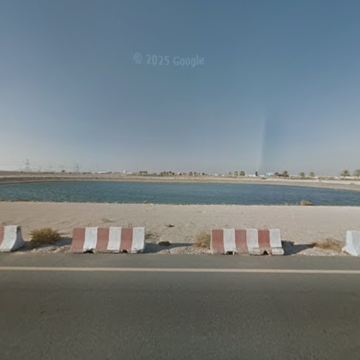

Fila 1 · país: AE · panoid: cPkUiQlxhNTfuRnMnWOWVg · image_id: cPkUiQlxhNTfuRnMnWOWVg_0


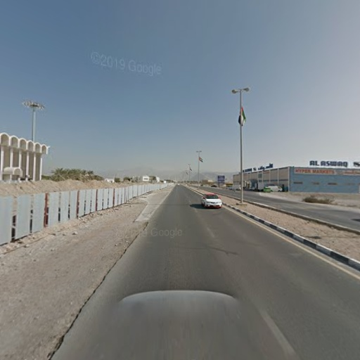

Fila 2 · país: AR · panoid: ip_sXJWNKU2CnOhqK9IG_g · image_id: ip_sXJWNKU2CnOhqK9IG_g_1


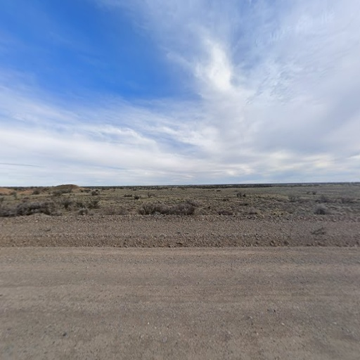

Fila 3 · país: AR · panoid: bC1P_2lUXgv4x7I2Fu9mQQ · image_id: bC1P_2lUXgv4x7I2Fu9mQQ_1


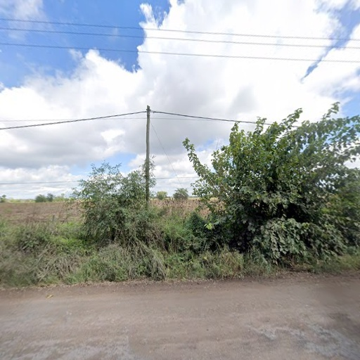

Fila 4 · país: AR · panoid: Zh6ADzYnOUvuA22vMLfyuQ · image_id: Zh6ADzYnOUvuA22vMLfyuQ_0


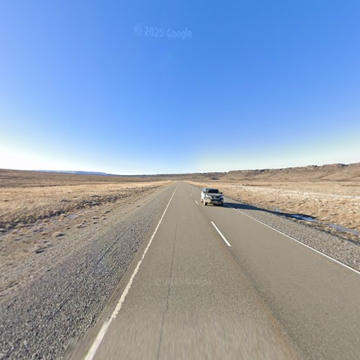

Fila 5 · país: AR · panoid: sPcbGyGrBp66OkAVf6Bpmg · image_id: sPcbGyGrBp66OkAVf6Bpmg_3


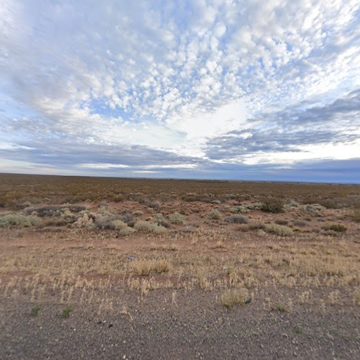

Fila 6 · país: AR · panoid: efQZIZtEH3-cWsUDrjl6-A · image_id: efQZIZtEH3-cWsUDrjl6-A_0


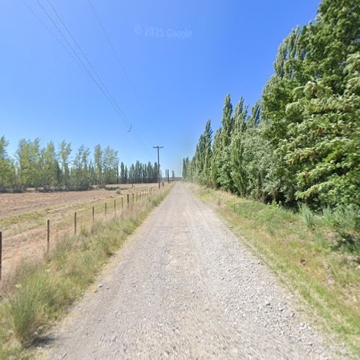

Fila 7 · país: AR · panoid: WB2mRtmAxSrzxFOzy5Hgyw · image_id: WB2mRtmAxSrzxFOzy5Hgyw_1


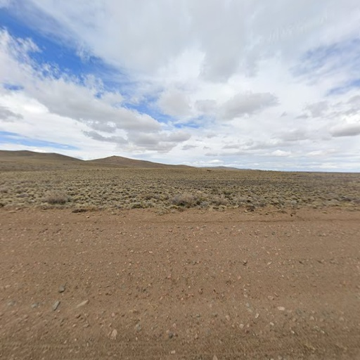

Fila 8 · país: AR · panoid: N8-oxyMoWb9li5zqCVK5_A · image_id: N8-oxyMoWb9li5zqCVK5_A_2


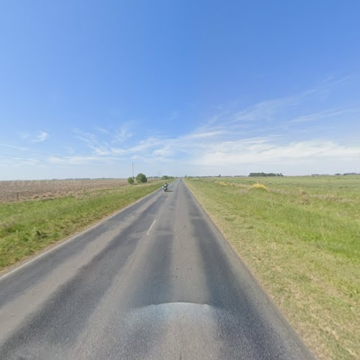

Fila 9 · país: AR · panoid: XjccGBKUPxdQ3Kk9cc5SLA · image_id: XjccGBKUPxdQ3Kk9cc5SLA_2


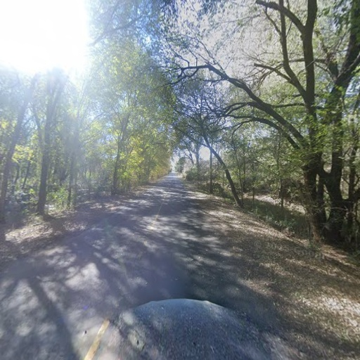

Fila 10 · país: AR · panoid: ymrkHQm4CQ388ziO_S1cuQ · image_id: ymrkHQm4CQ388ziO_S1cuQ_0


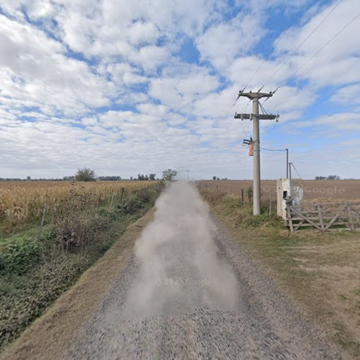

Fila 11 · país: AR · panoid: z-9d3kC7rAq0n4KQhP5ByA · image_id: z-9d3kC7rAq0n4KQhP5ByA_1


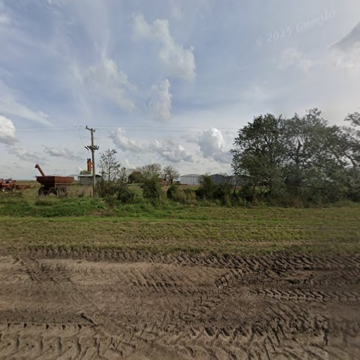

In [4]:
# Cambiar PAGINA y volver a ejecutar solamente esta celda.
if not isinstance(IMAGENES_POR_PAGINA, int) or not 1 <= IMAGENES_POR_PAGINA <= 48:
    raise ValueError("IMAGENES_POR_PAGINA debe estar entre 1 y 48.")
if not isinstance(PAGINA, int) or PAGINA < 1:
    raise ValueError("PAGINA debe ser un entero desde 1.")
if (len(TAMANO_MINIATURA) != 2
        or any(not isinstance(v, int) or not 1 <= v <= 1280 for v in TAMANO_MINIATURA)):
    raise ValueError("TAMANO_MINIATURA requiere dos enteros entre 1 y 1280.")
inicio = (PAGINA - 1) * IMAGENES_POR_PAGINA
fin = min(inicio + IMAGENES_POR_PAGINA, len(df_panoid))
paginas = max(1, (len(df_panoid) + IMAGENES_POR_PAGINA - 1) // IMAGENES_POR_PAGINA)
if PAGINA > paginas:
    raise ValueError(f"PAGINA fuera de rango: hay {paginas} páginas.")
clear_output(wait=True)
print(f"Página {PAGINA}/{paginas} · {len(df_panoid):,} filas en total")
tabla = df_panoid.iloc[inicio:fin].copy()
tabla.insert(0, "archivo_origen", [str(a) for a in archivos_origen[inicio:fin]])
display(tabla)

# Agrupar lecturas: un solo recorrido por grupo, sin acumular fotos originales.
seleccion = {}
for indice in range(inicio, fin):
    grupo, posicion = ubicaciones[indice]
    seleccion.setdefault((archivos_origen[indice], grupo), {})[posicion] = indice
miniaturas = {}
errores_imagenes = []
for (archivo, grupo), posiciones in seleccion.items():
    try:
        with pq.ParquetFile(archivo, pre_buffer=False) as parquet:
            if "image" not in parquet.schema_arrow.names:
                raise ValueError("Falta la columna image")
            for posicion, lote in enumerate(parquet.iter_batches(
                    batch_size=1, row_groups=[grupo], columns=["image"], use_threads=False)):
                if posicion in posiciones:
                    indice = posiciones[posicion]
                    try:
                        imagen_registro = lote.column("image")[0].as_py()
                        if not isinstance(imagen_registro, dict):
                            raise ValueError("Imagen ausente o formato no reconocido")
                        contenido = imagen_registro.get("bytes")
                        if contenido is not None:
                            origen = BytesIO(contenido)
                        else:
                            ruta = imagen_registro.get("path")
                            if not ruta:
                                raise ValueError("Imagen sin bytes ni ruta")
                            origen = Path(ruta).expanduser()
                            if not origen.is_absolute():
                                origen = archivo.parent / origen
                        with Image.open(origen) as imagen:
                            imagen.thumbnail(TAMANO_MINIATURA)
                            miniaturas[indice] = imagen.convert("RGB")
                    except (OSError, ValueError) as error:
                        errores_imagenes.append({"fila": indice, "error": str(error)})
                    finally:
                        imagen_registro = contenido = origen = None
                if posicion >= max(posiciones):
                    break
    except (OSError, ValueError) as error:
        errores_imagenes.append({"archivo": archivo.name, "error": str(error)})
try:
    for indice in range(inicio, fin):
        registro = filas[indice]
        print(f"Fila {indice} · país: {registro.get('country_code')} · panoid: {registro.get('panoid')} · image_id: {registro.get('image_id', '(sin image_id)')}")
        if indice in miniaturas:
            display(miniaturas[indice])
finally:
    for miniatura in miniaturas.values():
        miniatura.close()
    miniaturas.clear()
if errores_imagenes:
    display(pd.DataFrame(errores_imagenes))


In [5]:
# Resumen de todos los resultados encontrados, independientemente de la página.
if df_panoid.empty:
    print("No hay imágenes encontradas para resumir.")
elif "country_code" not in df_panoid:
    raise ValueError("Falta la columna country_code para agrupar por país.")
else:
    paises = df_panoid["country_code"].astype("string").str.strip().replace("", pd.NA)
    resumen_por_pais = (
        paises.fillna("Sin país")
        .value_counts()
        .rename_axis("pais")
        .reset_index(name="cantidad_imagenes")
        .sort_values(["cantidad_imagenes", "pais"], ascending=[False, True])
        .reset_index(drop=True)
    )
    print(f"Total de imágenes (filas encontradas): {len(df_panoid):,}")
    with pd.option_context("display.max_rows", None):
        display(resumen_por_pais)


Total de imágenes (filas encontradas): 1,995


,pais,cantidad_imagenes
0,US,426
1,IN,200
2,BR,153
3,AU,94
4,CA,80
5,RU,77
6,MX,57
7,AR,54
8,ID,53
9,FR,47
